# Phân tích khám phá dữ liệu khoa học - ZALO AI CHALLENGE


In [1]:
import sys
from pathlib import Path

SCRIPT_ROOT = Path.cwd() / 'src' / 'eda' / 'script'
if not SCRIPT_ROOT.exists():
    SCRIPT_ROOT = Path.cwd().resolve()
    for candidate in SCRIPT_ROOT.parents:
        if (candidate / 'src' / 'eda' / 'script').is_dir():
            SCRIPT_ROOT = candidate / 'src' / 'eda' / 'script'
            break
if str(SCRIPT_ROOT) not in sys.path:
    sys.path.insert(0, str(SCRIPT_ROOT))

from IPython.display import HTML, Markdown, display

from common.config import load_config
from orchestration.pipeline import run_eda

config = load_config()
run = run_eda(config)
run.run_id


'20261029T155046Z_aa5c21e3'

In [2]:
def _show_figure(chart_id, split='train', limit=1):
    html = run.figures_html(chart_id, split, limit)
    if html:
        display(HTML(html))


In [3]:
def _show_table(table_id, split=None):
    html = run.table_html(table_id, split)
    if not html:
        print(f'Bảng {table_id} không có dữ liệu cho split {split}')
        return
    display(HTML(html))


## 00. Cấu hình, chạy pipeline và provenance

**Mục tiêu:** Xác lập cấu hình, chạy pipeline EDA một lần và hiển thị ledger kiểm định cùng provenance của toàn bộ artifact sinh ra.

**Phương pháp:** Pipeline đọc nguồn ở chế độ chỉ đọc, tính toàn bộ chỉ số tại thời điểm nạp dữ liệu và ghi registry có hash cho từng artifact.

**Cách đọc và hạn chế:** Mọi con số trong notebook đều truy vết được về run_id, source hash và phương pháp tính; không có số liệu nào nhập tay.


In [4]:
_show_table('TBL20')


phase,gate,status,reason,owner,artifact
IMP-00,workspace_audit,PASS,"workspace root, raw root and output containment verified",orchestration.pipeline,run_manifest.json
IMP-01,split_inventory_train,PASS,"162 source files, 30 businesses, 302 worksheets, 17 database objects",orchestration.pipeline,file_manifest.json
IMP-02,schema_discovery_train,PASS,"2932 typed columns, 16712 key candidates, 294 relation candidates",orchestration.pipeline,column_registry.json
IMP-03,data_quality_train,PASS,"741 missingness entries, 590 duplicate classes, 36 validity rules, 1550 compiled findings",orchestration.pipeline,quality_findings.json
IMP-04,statistics_train,PASS,"602 numeric measures, 16492 categorical profiles",orchestration.pipeline,numeric_stats.json
IMP-05,temporal_train,PASS,"256 date columns, 256 coverage windows",orchestration.pipeline,temporal_profile.json
IMP-06,business_profiles_train,PASS,"30 business profiles, 30 domain diagnostics, 480 metric definitions",orchestration.pipeline,business_profile_index.json
IMP-07,question_metadata_train,PASS,3000 questions profiled; reference answers profiled in aggregated metadata form,orchestration.pipeline,question_profile.json
IMP-01,split_inventory_public_test,PASS,"97 source files, 14 businesses, 136 worksheets, 17 database objects",orchestration.pipeline,file_manifest.json
IMP-02,schema_discovery_public_test,PASS,"1445 typed columns, 7924 key candidates, 174 relation candidates",orchestration.pipeline,column_registry.json


## 01. Tổng quan bộ dữ liệu

**Mục tiêu:** Mô tả phạm vi dữ liệu theo split, đơn vị đếm và mức độ bao phủ của từng doanh nghiệp.

**Phương pháp:** Đếm đối tượng siêu dữ liệu từ manifest và registry của từng split; số tệp và số giao dịch là hai đại lượng khác nhau.

**Cách đọc và hạn chế:** Tổng số tệp, số worksheet và số đối tượng CSDL là số đối tượng nguồn, không phải số giao dịch và không được cộng chéo.


split,status,source_count,business_count,worksheet_count,database_object_count
train,PASS,162,30,302,17
public_test,PASS,97,14,136,17



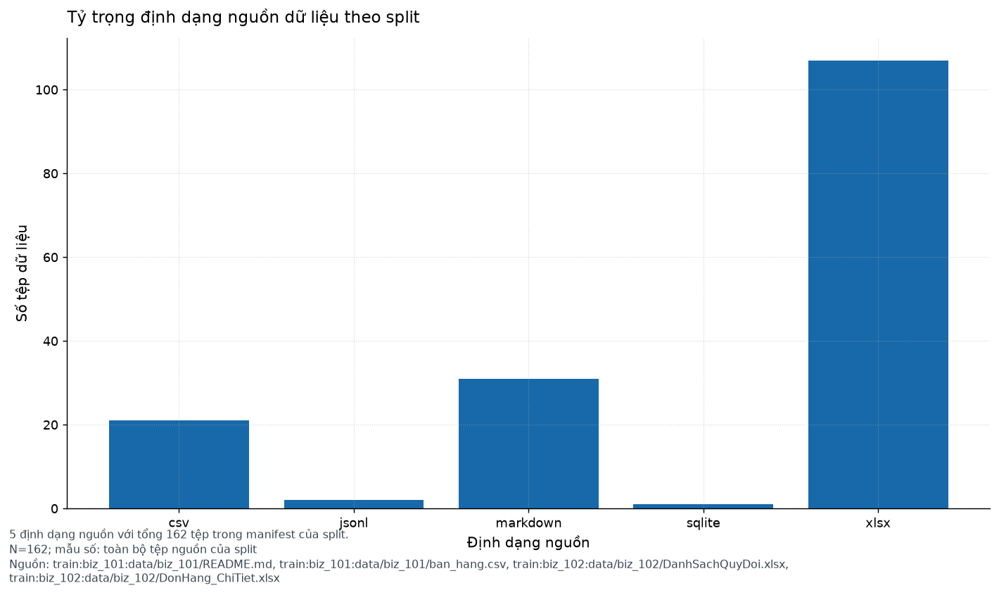


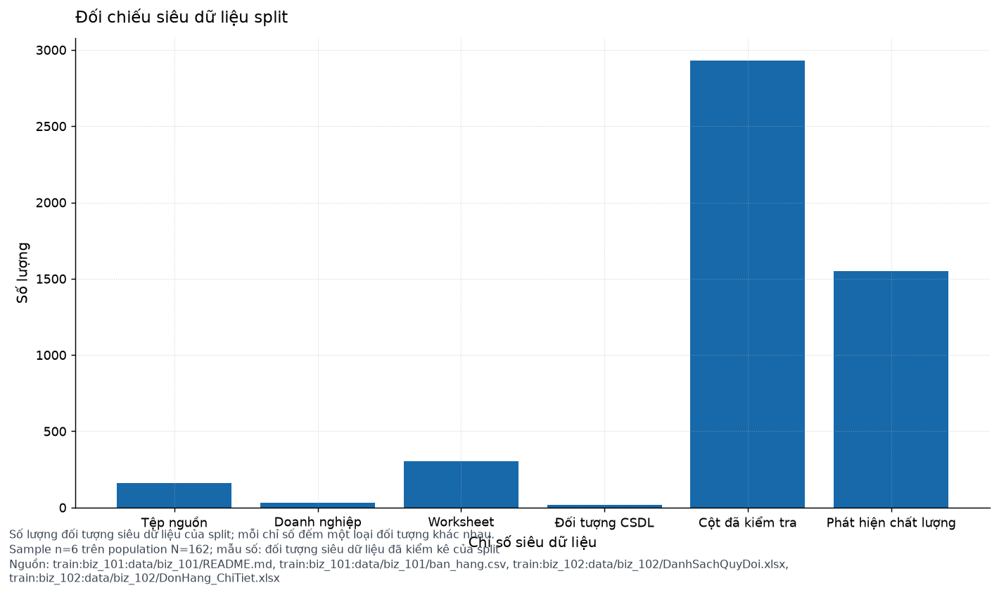

In [5]:
_show_table('TBL01')

_show_figure('INV01', 'train', 1)
_show_figure('GLOBAL06', 'train', 1)


## 02. Kiểm kê nguồn dữ liệu

**Mục tiêu:** Liệt kê toàn bộ tệp, worksheet và đối tượng CSDL kèm trạng thái đọc, hash và siêu dữ liệu cấu trúc.

**Phương pháp:** Registry kiểm kê gom từ manifest nguồn và registry worksheet/database; mỗi bản ghi gắn content hash của tệp gốc.

**Cách đọc và hạn chế:** Nhiều tệp hơn không đồng nghĩa nhiều giao dịch hơn; tệp trong manifest được đọc ở chế độ chỉ đọc và không bị thay đổi.


source_id,split,business_id,source_type,logical_path,size_bytes,content_hash,status
train:biz_101:data/biz_101/README.md,train,biz_101,markdown,data/biz_101/README.md,4262,sha256:c71cf95a70eb10d08546bbf7755d55509d6410e009119579c4528720dadb125a,PASS
train:biz_101:data/biz_101/ban_hang.csv,train,biz_101,csv,data/biz_101/ban_hang.csv,5356971,sha256:0c52e0f7becc6b4e928793f564b8d61809cd1f8cc03e40683c84e8ec12bc8e5f,PASS
train:biz_102:data/biz_102/DanhSachQuyDoi.xlsx,train,biz_102,xlsx,data/biz_102/DanhSachQuyDoi.xlsx,7331,sha256:9446644c5e207599c027e7714a06e118307568bb5d06a2f66246f6d500a6b22e,PASS
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx,train,biz_102,xlsx,data/biz_102/DonHang_ChiTiet.xlsx,4164123,sha256:81040a59e3cd95f9f1d02c942d7a636be4f476676e5917c15ff8529ee4bbd1f7,PASS
train:biz_102:data/biz_102/README.md,train,biz_102,markdown,data/biz_102/README.md,1562,sha256:6d857ce98b60e60a31147247c7339a5d9ac935987da3042faa14fb4022e04551,PASS
train:biz_103:data/biz_103/DanhSachQuyDoi.xlsx,train,biz_103,xlsx,data/biz_103/DanhSachQuyDoi.xlsx,7331,sha256:9446644c5e207599c027e7714a06e118307568bb5d06a2f66246f6d500a6b22e,PASS
train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx,train,biz_103,xlsx,data/biz_103/DonHang_ChiTiet.xlsx,1732323,sha256:eba63ea1f9a684e0064a18d1728d2848761db398520464177daf5fe4c11aa7e1,PASS
train:biz_103:data/biz_103/README.md,train,biz_103,markdown,data/biz_103/README.md,1239,sha256:2dcc4d7968fd2d7b74bf4ee2aae5f2bfca9dbdac69346148325e2ae8d82b3622,PASS
train:biz_104:data/biz_104/DanhSachQuyDoi.xlsx,train,biz_104,xlsx,data/biz_104/DanhSachQuyDoi.xlsx,4974,sha256:5078c10892c20f1e34c750e42aa66ef5f3d159eb0d22c37f84a727e98cb6852a,PASS
train:biz_104:data/biz_104/DonHang_ChiTiet.xlsx,train,biz_104,xlsx,data/biz_104/DonHang_ChiTiet.xlsx,2712353,sha256:0f233d852b41e2e19cb4e3df3c7926bbcf123d75ca723763411ce84bafebf386,PASS


workbook_path,sheet_name,sheet_state,data_row_count,header_confidence,max_column,has_repeated_header,formula_cell_count
data/biz_102/DanhSachQuyDoi.xlsx,Sheet1,visible,77,1,4,false,0
data/biz_102/DonHang_ChiTiet.xlsx,T01_2025,visible,6674,1,9,false,0
data/biz_102/DonHang_ChiTiet.xlsx,T02_2025,visible,5960,1,9,false,0
data/biz_102/DonHang_ChiTiet.xlsx,T03_2025,visible,4785,1,9,false,0
data/biz_102/DonHang_ChiTiet.xlsx,T04_2025,visible,4587,1,9,false,0
data/biz_102/DonHang_ChiTiet.xlsx,T05_2025,visible,4575,1,9,false,0
data/biz_102/DonHang_ChiTiet.xlsx,T06_2025,visible,4287,1,9,false,0
data/biz_102/DonHang_ChiTiet.xlsx,T07_2025,visible,4568,1,9,false,0
data/biz_102/DonHang_ChiTiet.xlsx,T08_2025,visible,4626,1,9,false,0
data/biz_102/DonHang_ChiTiet.xlsx,T09_2025,visible,4410,1,9,false,0


database_path,object_type,object_name,primary_key,row_count,column_count,foreign_key_count
data/biz_123/pos.sqlite,table,chi_nhanh,none,1,5,0
data/biz_123/pos.sqlite,table,chi_tiet_don,none,64149,11,0
data/biz_123/pos.sqlite,table,chi_tiet_don_lo,none,64422,6,0
data/biz_123/pos.sqlite,table,chi_tiet_nhap,none,2953,9,0
data/biz_123/pos.sqlite,table,don_hang,none,33630,22,0
data/biz_123/pos.sqlite,table,don_vi_sp,none,83,5,0
data/biz_123/pos.sqlite,table,khach_hang,none,300,18,0
data/biz_123/pos.sqlite,table,lich_su_gia,none,109,4,0
data/biz_123/pos.sqlite,table,lo_hang,none,2953,7,0
data/biz_123/pos.sqlite,table,nha_cung_cap,none,5,5,0



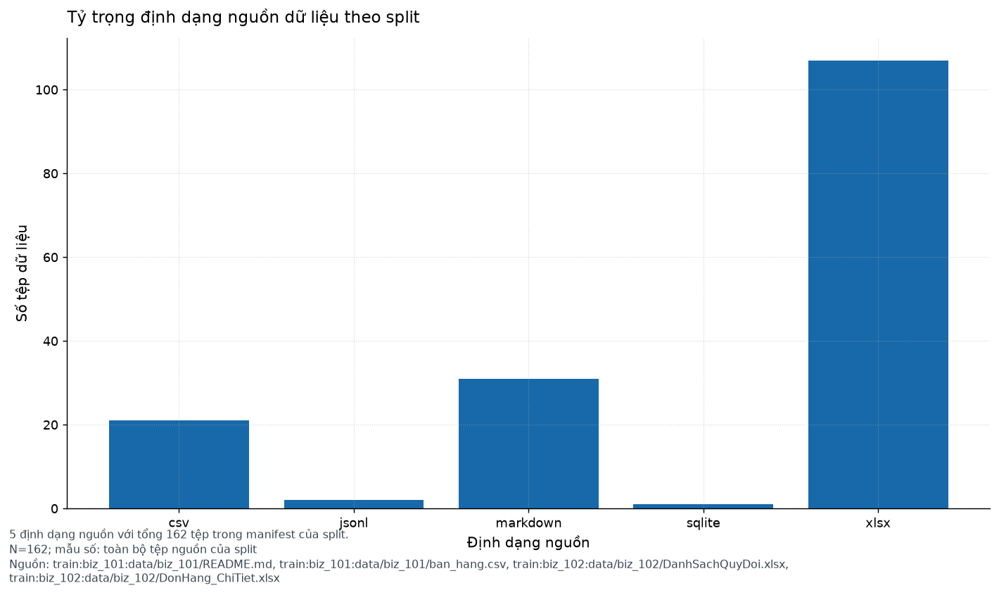


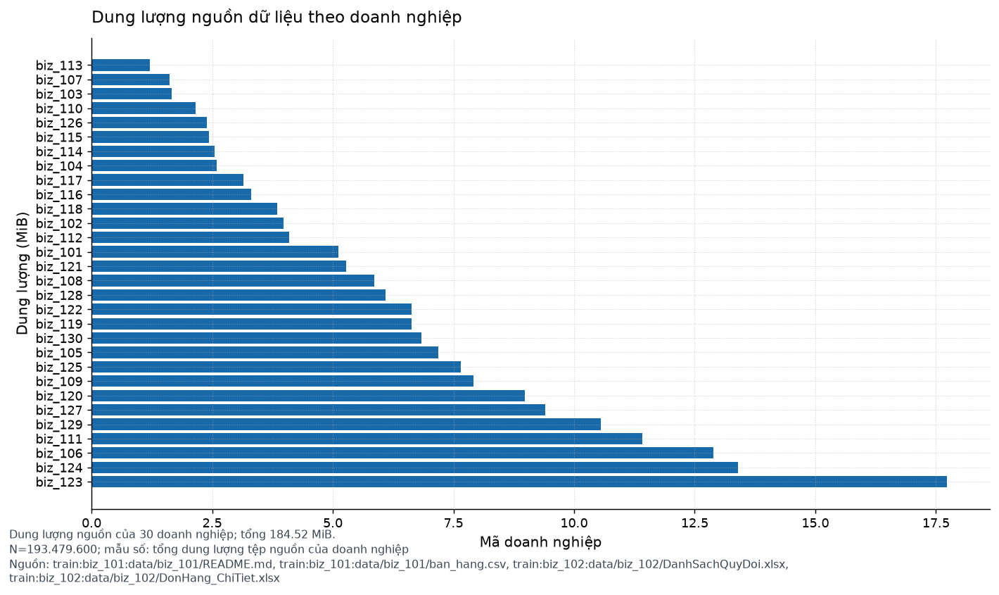


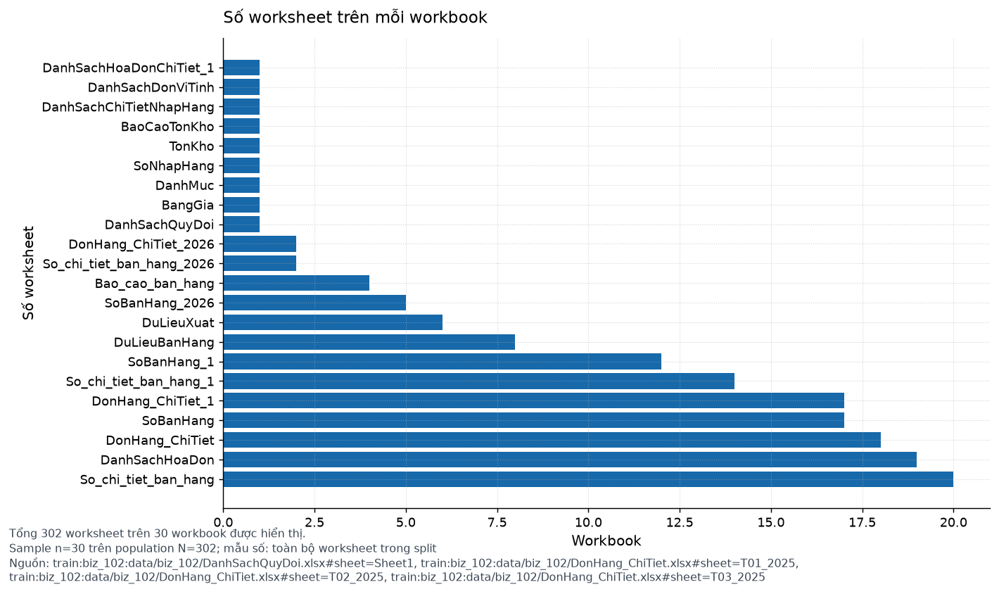


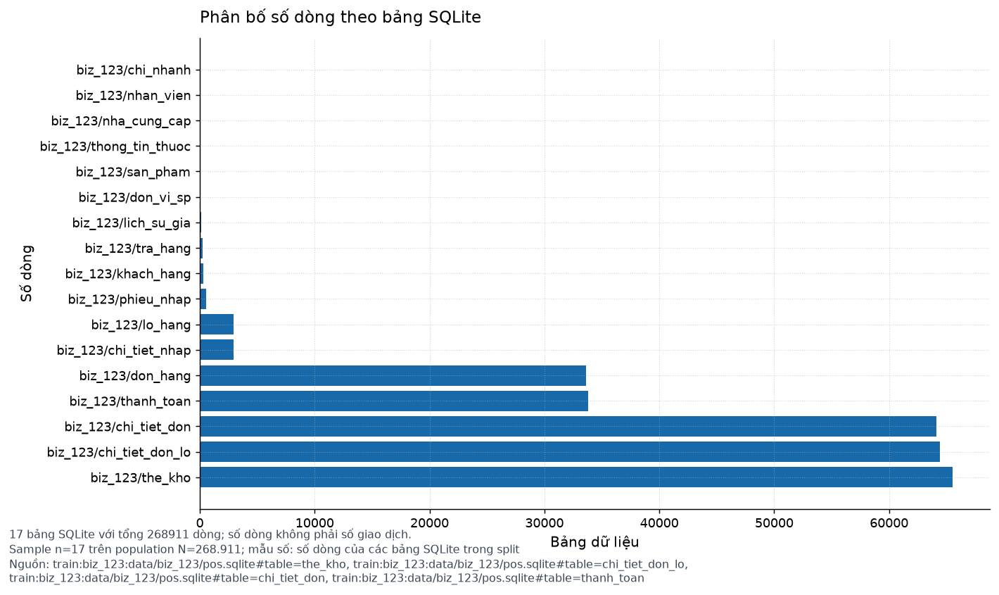

In [6]:
_show_table('TBL02', 'train')
_show_table('TBL03', 'train')
_show_table('TBL04', 'train')

_show_figure('INV01', 'train', 1)
_show_figure('INV02', 'train', 1)
_show_figure('INV03', 'train', 1)
_show_figure('INV04', 'train', 1)


## 03. Khám phá schema và mối quan hệ

**Mục tiêu:** Xác định kiểu vật lý và ngữ nghĩa của từng cột, cùng bằng chứng khóa chính và quan hệ giữa các bảng.

**Phương pháp:** Suy luận kiểu dữ liệu trên toàn bộ dòng đã đọc, kết hợp bằng chứng khóa ứng viên và kiểm tra số khóa lệch.

**Cách đọc và hạn chế:** Quan hệ ứng viên chưa được phê duyệt không được dùng để tính chỉ số; phép nối có rủi ro nhân bản bị chặn theo thiết kế.


source_id,column,physical_type,semantic_type,unit,parse_failure_n,business_id,non_null_n,null_n,distinct_n,confidence
train:biz_101:data/biz_101/ban_hang.csv,Giá bán,integer,amount,VND,0,biz_101,5000,0,76,1
train:biz_101:data/biz_101/ban_hang.csv,Kết quả,category,categorical,none,0,biz_101,5000,0,3,0.0006
train:biz_101:data/biz_101/ban_hang.csv,Nội dung,category,categorical,none,0,biz_101,5000,0,70,0.014
train:biz_101:data/biz_101/ban_hang.csv,Ngày tháng,category,categorical,none,0,biz_101,5000,0,45,0.009
train:biz_101:data/biz_101/ban_hang.csv,Đơn vị (tính),category,categorical,none,0,biz_101,5000,0,16,0.0032
train:biz_101:data/biz_101/ban_hang.csv,so_luong,integer,unknown,none,0,biz_101,5000,0,9,1
train:biz_101:data/biz_101/ban_hang.csv,Thanh tien,integer,amount,VND,0,biz_101,5000,0,201,1
train:biz_101:data/biz_101/ban_hang.csv,Quy ra ĐV lẻ,integer,unknown,none,0,biz_101,5000,0,29,1
train:biz_101:data/biz_101/ban_hang.csv,Mã hóa đơn,text,text,none,0,biz_101,5000,0,1974,1
train:biz_101:data/biz_101/ban_hang.csv,Đối tác,category,categorical,none,0,biz_101,5000,0,260,0.052


left_source,right_source,join_keys,matched_rows,unmatched_left_rows,duplicate_key_left,fanout_factor,status,relation_id,left_grain,right_grain,unmatched_right_rows,duplicate_key_right,risk
train:biz_102:data/biz_102/DanhSachQuyDoi.xlsx#sheet=Sheet1,train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T01_2025,"Tên sản phẩm, Tên sản phẩm",59,0,18,86.6753,CANDIDATE,train.biz_102.Sheet1__Tên sản phẩm_Tên sản phẩm__T01_2025,one row per Sheet1,one row per T01_2025,1,6614,duplicate_keys_may_cause_fanout
train:biz_102:data/biz_102/DanhSachQuyDoi.xlsx#sheet=Sheet1,train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T02_2025,"Tên sản phẩm, Tên sản phẩm",59,0,18,77.4026,CANDIDATE,train.biz_102.Sheet1__Tên sản phẩm_Tên sản phẩm__T02_2025,one row per Sheet1,one row per T02_2025,1,5900,duplicate_keys_may_cause_fanout
train:biz_102:data/biz_102/DanhSachQuyDoi.xlsx#sheet=Sheet1,train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T03_2025,"Tên sản phẩm, Tên sản phẩm",59,0,18,62.1429,CANDIDATE,train.biz_102.Sheet1__Tên sản phẩm_Tên sản phẩm__T03_2025,one row per Sheet1,one row per T03_2025,1,4725,duplicate_keys_may_cause_fanout
train:biz_102:data/biz_102/DanhSachQuyDoi.xlsx#sheet=Sheet1,train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T04_2025,"Tên sản phẩm, Tên sản phẩm",59,0,18,59.5714,CANDIDATE,train.biz_102.Sheet1__Tên sản phẩm_Tên sản phẩm__T04_2025,one row per Sheet1,one row per T04_2025,1,4527,duplicate_keys_may_cause_fanout
train:biz_102:data/biz_102/DanhSachQuyDoi.xlsx#sheet=Sheet1,train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T05_2025,"Tên sản phẩm, Tên sản phẩm",59,0,18,59.4156,CANDIDATE,train.biz_102.Sheet1__Tên sản phẩm_Tên sản phẩm__T05_2025,one row per Sheet1,one row per T05_2025,1,4515,duplicate_keys_may_cause_fanout
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T01_2025,train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T02_2025,"Mã đơn hàng, Mã đơn hàng",0,2711,3963,0.893,REJECTED,train.biz_102.T01_2025__Mã đơn hàng_Mã đơn hàng__T02_2025,one row per T01_2025,one row per T02_2025,2367,3593,no_key_overlap
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T01_2025,train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T02_2025,"Ngày đặt hàng, Ngày đặt hàng",0,31,6643,0.893,REJECTED,train.biz_102.T01_2025__Ngày đặt hàng_Ngày đặt hàng__T02_2025,one row per T01_2025,one row per T02_2025,28,5932,no_key_overlap
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T01_2025,train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T03_2025,"Mã đơn hàng, Mã đơn hàng",0,2711,3963,0.717,REJECTED,train.biz_102.T01_2025__Mã đơn hàng_Mã đơn hàng__T03_2025,one row per T01_2025,one row per T03_2025,1887,2898,no_key_overlap
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T01_2025,train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T03_2025,"Ngày đặt hàng, Ngày đặt hàng",0,31,6643,0.717,REJECTED,train.biz_102.T01_2025__Ngày đặt hàng_Ngày đặt hàng__T03_2025,one row per T01_2025,one row per T03_2025,31,4754,no_key_overlap
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T01_2025,train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T04_2025,"Mã đơn hàng, Mã đơn hàng",0,2711,3963,0.6873,REJECTED,train.biz_102.T01_2025__Mã đơn hàng_Mã đơn hàng__T04_2025,one row per T01_2025,one row per T04_2025,1769,2818,no_key_overlap



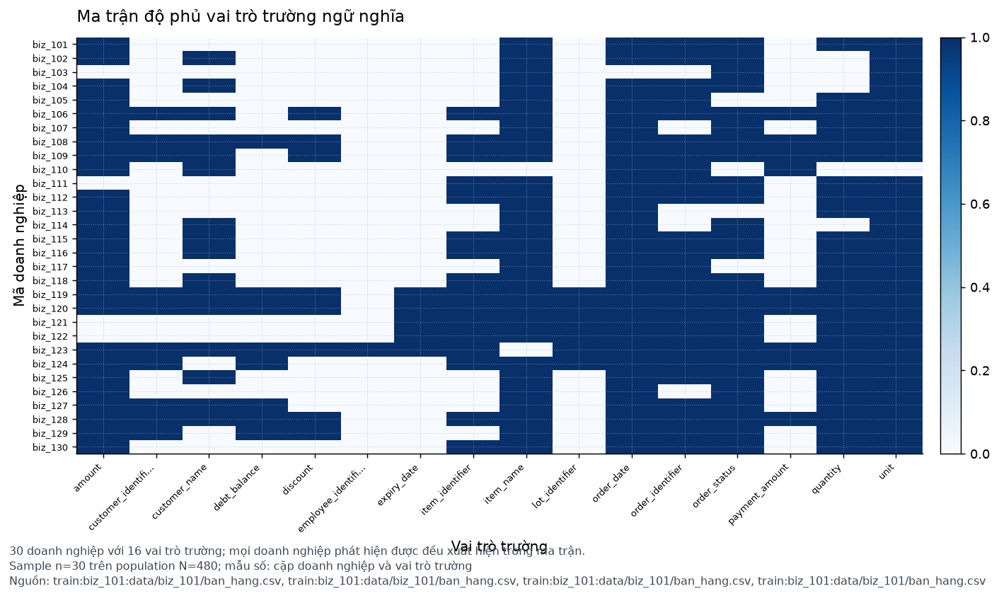


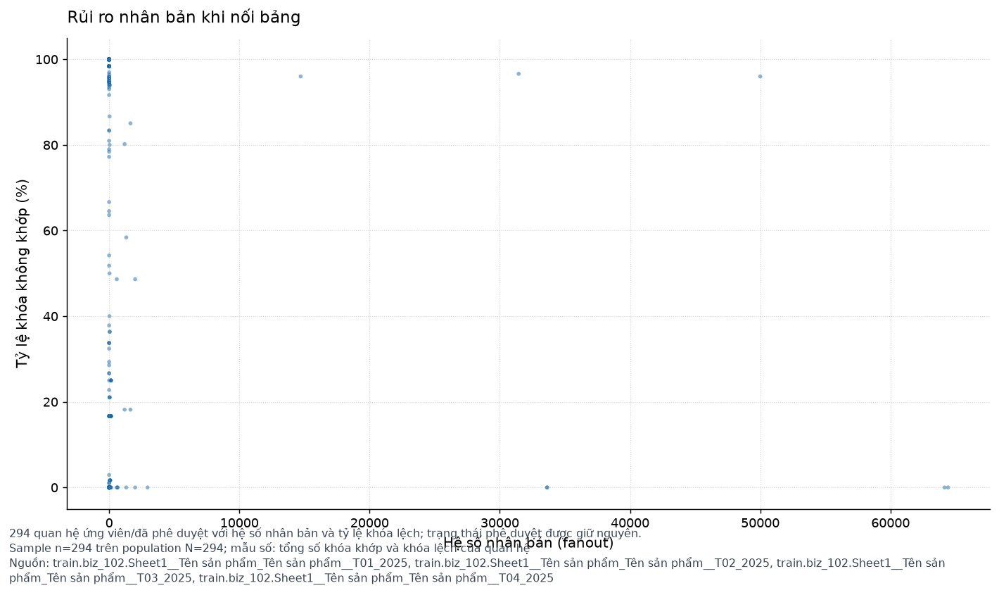

In [7]:
_show_table('TBL05', 'train')
_show_table('TBL12', 'train')

_show_figure('GLOBAL02', 'train', 1)
_show_figure('QUAL07', 'train', 1)


## 04. Chất lượng dữ liệu

**Mục tiêu:** Đo mức thiếu dữ liệu, trùng lặp, vi phạm quy tắc và mức độ phát hiện theo từng nguồn, kèm mẫu số rõ ràng.

**Phương pháp:** Mọi tỷ lệ đều chia cho mẫu số của chính trường hoặc chính quy tắc được hồ sơ; thiếu dữ liệu có cấu trúc tách riêng khỏi khoảng trống thực.

**Cách đọc và hạn chế:** Cờ thiếu dữ liệu và cờ trùng lặp là tín hiệu thống kê, chưa được xác định là bản ghi lỗi nếu chưa có đối chiếu rulebook.


source_id,column,n_missing,n_total,missing_ratio,null_kind,business_id,co_missing_with
train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=04.2025,Trạng thái đơn hàng,1655,2754,0.600944,blank_or_not_applicable,biz_103,Đặt hàng (Đã duyệt)
train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=04.2025,Đặt hàng (Đã duyệt),1655,2754,0.600944,blank_or_not_applicable,biz_103,Trạng thái đơn hàng
train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=05.2025,Trạng thái đơn hàng,1720,2847,0.604145,blank_or_not_applicable,biz_103,Đặt hàng (Đã duyệt)
train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=05.2025,Đặt hàng (Đã duyệt),1720,2847,0.604145,blank_or_not_applicable,biz_103,Trạng thái đơn hàng
train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=06.2025,Trạng thái đơn hàng,1564,2636,0.593323,blank_or_not_applicable,biz_103,Đặt hàng (Đã duyệt)
train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=06.2025,Đặt hàng (Đã duyệt),1564,2636,0.593323,blank_or_not_applicable,biz_103,Trạng thái đơn hàng
train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=07.2025,Trạng thái đơn hàng,1680,2787,0.602799,blank_or_not_applicable,biz_103,Đặt hàng (Đã duyệt)
train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=07.2025,Đặt hàng (Đã duyệt),1680,2787,0.602799,blank_or_not_applicable,biz_103,Trạng thái đơn hàng
train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=08.2025,Trạng thái đơn hàng,1783,2919,0.610826,blank_or_not_applicable,biz_103,Đặt hàng (Đã duyệt)
train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=08.2025,Đặt hàng (Đã duyệt),1783,2919,0.610826,blank_or_not_applicable,biz_103,Trạng thái đơn hàng


source_id,duplicate_class,n_duplicate_rows,total_n,explanation,business_id,key_columns,n_distinct_keys
train:biz_101:data/biz_101/ban_hang.csv,exact_row,0,56501,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,biz_101,all columns,56501
train:biz_101:data/biz_101/ban_hang.csv,business_key,0,56501,rows sharing the candidate business key; duplicates are valid when the grain is line-item and invalid when the grain is order,biz_101,"Nội dung, Mã hóa đơn",56501
train:biz_102:data/biz_102/DanhSachQuyDoi.xlsx#sheet=Sheet1,exact_row,0,77,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,biz_102,all columns,77
train:biz_102:data/biz_102/DanhSachQuyDoi.xlsx#sheet=Sheet1,business_key,0,77,rows sharing the candidate business key; duplicates are valid when the grain is line-item and invalid when the grain is order,biz_102,"Tên sản phẩm, Đơn vị quy đổi",77
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T01_2025,exact_row,0,6674,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,biz_102,all columns,6674
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T01_2025,business_key,0,6674,rows sharing the candidate business key; duplicates are valid when the grain is line-item and invalid when the grain is order,biz_102,"Mã đơn hàng, Tên sản phẩm",6674
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T02_2025,exact_row,0,5960,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,biz_102,all columns,5960
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T02_2025,business_key,0,5960,rows sharing the candidate business key; duplicates are valid when the grain is line-item and invalid when the grain is order,biz_102,"Mã đơn hàng, Tên sản phẩm",5960
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T03_2025,exact_row,0,4785,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,biz_102,all columns,4785
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T03_2025,business_key,0,4785,rows sharing the candidate business key; duplicates are valid when the grain is line-item and invalid when the grain is order,biz_102,"Mã đơn hàng, Tên sản phẩm",4785


source_id,column,rule_id,invalid_count,denominator,evidence,business_id,invalid_ratio,severity,sample_masked
train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=04.2025,Đặt hàng (Đã duyệt),VAL.DATE.PARSE,1,1099,value could not be interpreted as a calendar date,biz_103,0.00091,medium,N***********g
train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=05.2025,Đặt hàng (Đã duyệt),VAL.DATE.PARSE,1,1127,value could not be interpreted as a calendar date,biz_103,0.000887,medium,N***********g
train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=06.2025,Đặt hàng (Đã duyệt),VAL.DATE.PARSE,1,1072,value could not be interpreted as a calendar date,biz_103,0.000933,medium,N***********g
train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=07.2025,Đặt hàng (Đã duyệt),VAL.DATE.PARSE,1,1107,value could not be interpreted as a calendar date,biz_103,0.000903,medium,N***********g
train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=08.2025,Đặt hàng (Đã duyệt),VAL.DATE.PARSE,1,1136,value could not be interpreted as a calendar date,biz_103,0.00088,medium,N***********g
train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=09.2025,Đặt hàng (Đã duyệt),VAL.DATE.PARSE,1,1129,value could not be interpreted as a calendar date,biz_103,0.000886,medium,N***********g
train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=10.2025,Đặt hàng (Đã duyệt),VAL.DATE.PARSE,1,1145,value could not be interpreted as a calendar date,biz_103,0.000873,medium,N***********g
train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=11.2025,Đặt hàng (Đã duyệt),VAL.DATE.PARSE,1,1184,value could not be interpreted as a calendar date,biz_103,0.000845,medium,N***********g
train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=12.2025,Đặt hàng (Đã duyệt),VAL.DATE.PARSE,1,1109,value could not be interpreted as a calendar date,biz_103,0.000902,medium,N***********g
train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=01.2026,Đặt hàng (Đã duyệt),VAL.DATE.PARSE,1,1208,value could not be interpreted as a calendar date,biz_103,0.000828,medium,N***********g


finding_id,severity,domain,business_id,count,denominator,evidence,status,source_id,field,ratio,hypothesis,alternative_explanation,verification
DUP.train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=01.2026.exact_row,high,uniqueness,biz_103,1728,2937,exact_row duplicates=1728 distinct_keys=1209,PARTIAL,train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=01.2026,none,0.588355,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=02.2026.exact_row,high,uniqueness,biz_103,2861,4735,exact_row duplicates=2861 distinct_keys=1874,PARTIAL,train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=02.2026,none,0.604224,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=03.2026.exact_row,high,uniqueness,biz_103,1727,2904,exact_row duplicates=1727 distinct_keys=1177,PARTIAL,train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=03.2026,none,0.594697,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=04.2025.exact_row,high,uniqueness,biz_103,1654,2754,exact_row duplicates=1654 distinct_keys=1100,PARTIAL,train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=04.2025,none,0.600581,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=04.2026.exact_row,high,uniqueness,biz_103,1837,3004,exact_row duplicates=1837 distinct_keys=1167,PARTIAL,train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=04.2026,none,0.611518,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=05.2025.exact_row,high,uniqueness,biz_103,1719,2847,exact_row duplicates=1719 distinct_keys=1128,PARTIAL,train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=05.2025,none,0.603793,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=05.2026.exact_row,high,uniqueness,biz_103,1710,2855,exact_row duplicates=1710 distinct_keys=1145,PARTIAL,train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=05.2026,none,0.598949,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=06.2025.exact_row,high,uniqueness,biz_103,1563,2636,exact_row duplicates=1563 distinct_keys=1073,PARTIAL,train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=06.2025,none,0.592944,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=06.2026.exact_row,high,uniqueness,biz_103,1659,2759,exact_row duplicates=1659 distinct_keys=1100,PARTIAL,train:biz_103:data/biz_103/DonHang_Chi


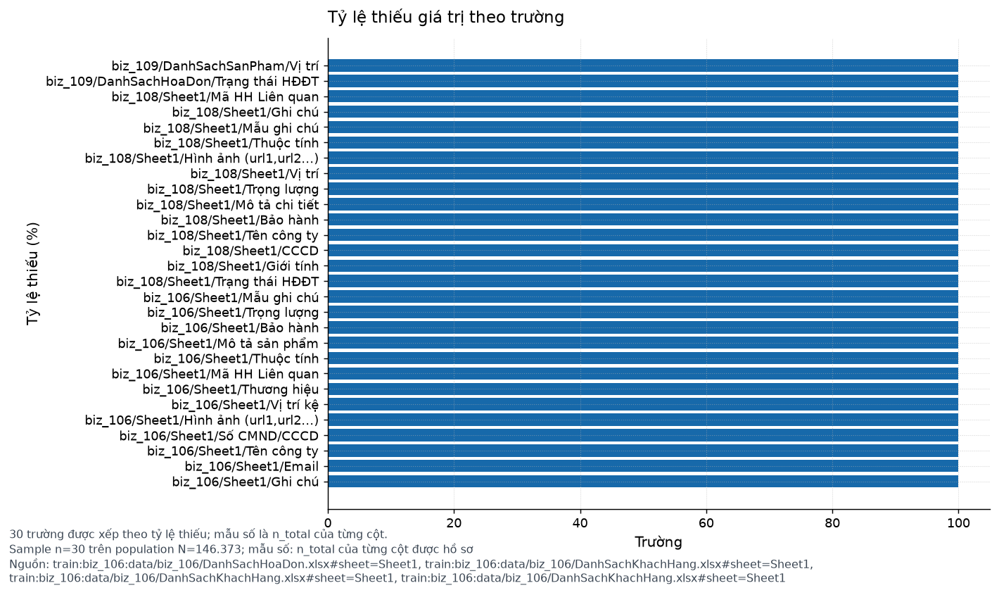


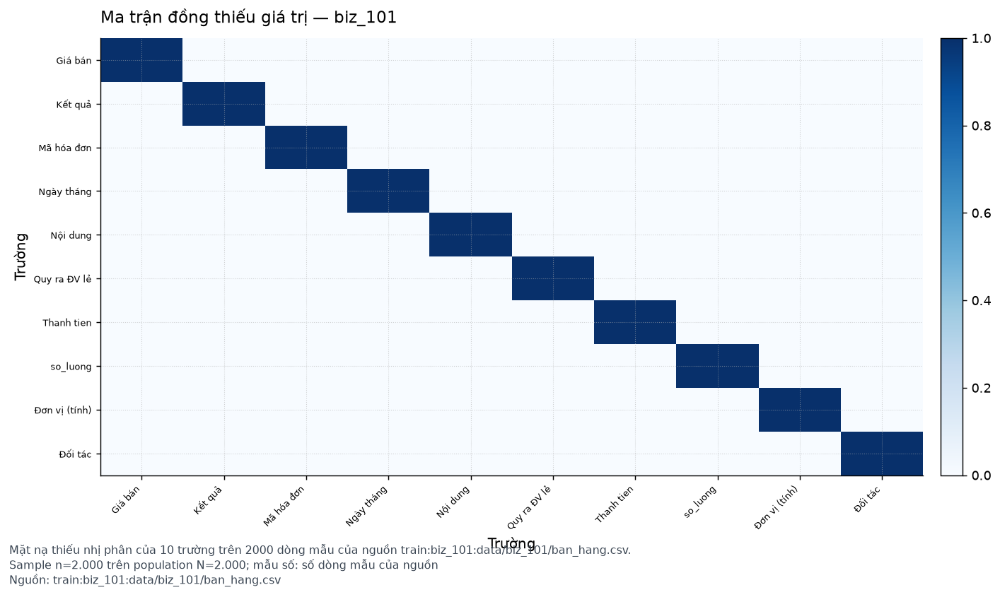


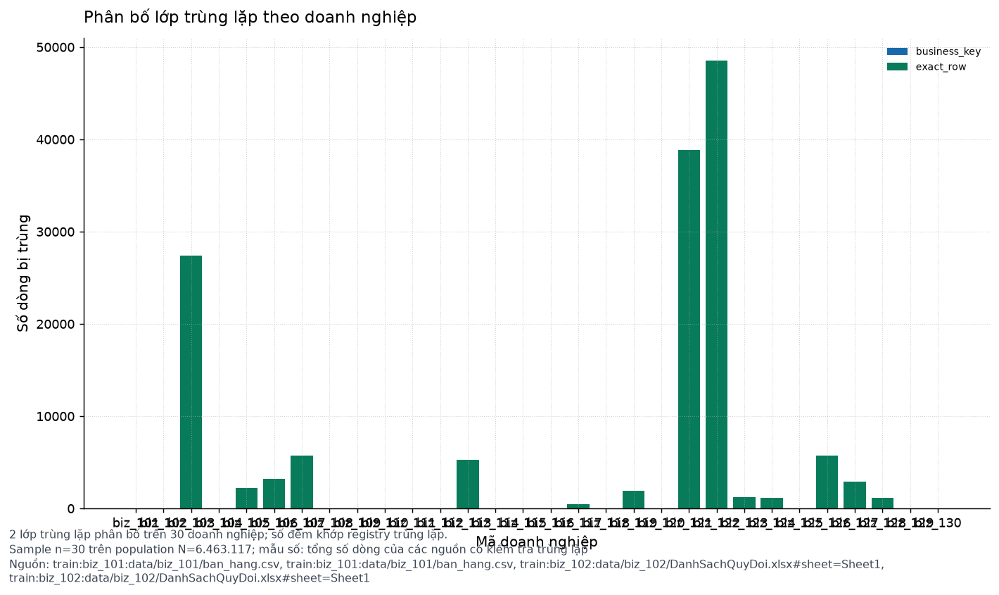


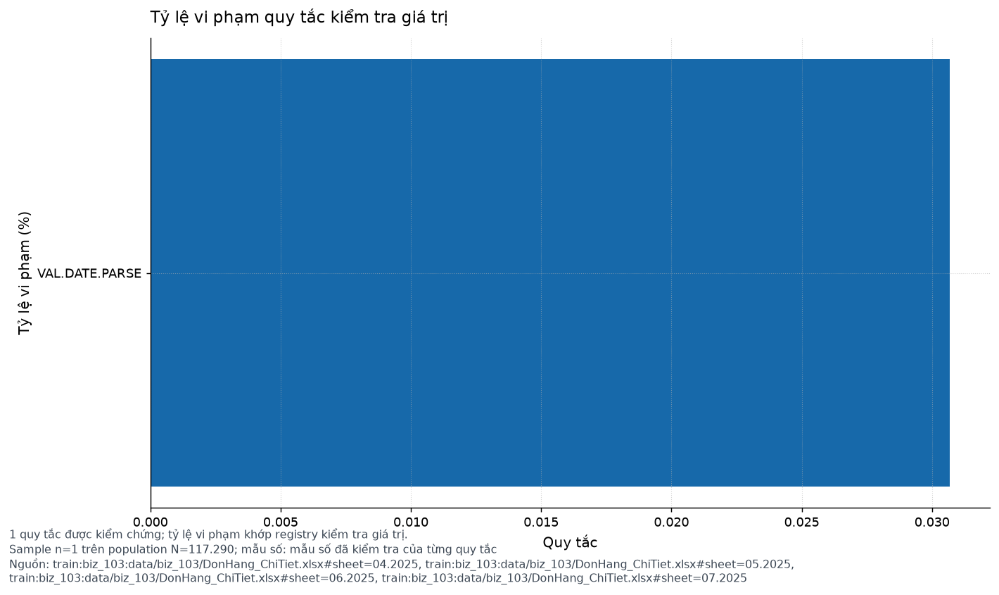

#### Thẻ chuyện `BUS01` — biz_101 (train)

1. **Mục tiêu:** Giá trị đơn hàng phân bố như thế nào?
2. **Bối cảnh:** split = train; doanh nghiệp = biz_101; nguồn = ('train:biz_101:data/biz_101/ban_hang.csv',); đơn vị quan sát = business_id
3. **Phương pháp:** phương pháp = valid_order_amount_distribution; quy tắc lọc = phân phối giá trị đơn hàng hợp lệ; xử lý giá trị khuyết = EXCLUDE_FROM_MEASURE_WITH_COUNT; xử lý ngoại lệ = RETAIN_AND_FLAG
4. **Bảng thống kê:**
   - population_n = 22428
   - n_valid = 22428
   - đơn vị = VND
   - phương pháp = valid_order_amount_distribution
   - công thức = phân phối giá trị đơn hàng hợp lệ
   - lấy mẫu = FULL_AGGREGATION
5. **Biểu đồ:** figures/20261029T155046Z_aa5c21e3/train/biz_101/BUS01.png
6. **Nhận xét:**
   - Trong `biz_101` thuộc split `public_test`, chỉ số `BUS01 — ban_hang.csv` có giá trị `66.000` `VND` trên `22.428` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T01_2025` có giá trị `66.000` `VND` trên `2.711` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T02_2025` có giá trị `65.000` `VND` trên `2.367` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T03_2025` có giá trị `66.000` `VND` trên `1.887` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T04_2025` có giá trị `67.500` `VND` trên `1.769` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T05_2025` có giá trị `65.000` `VND` trên `1.876` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T06_2025` có giá trị `64.500` `VND` trên `1.729` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T07_2025` có giá trị `65.000` `VND` trên `1.848` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T08_2025` có giá trị `68.000` `VND` trên `1.833` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T09_2025` có giá trị `67.000` `VND` trên `1.755` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T10_2025` có giá trị `69.000` `VND` trên `1.869` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T11_2025` có giá trị `74.000` `VND` trên `1.768` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T12_2025` có giá trị `65.000` `VND` trên `1.783` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T01_2026` có giá trị `71.400` `VND` trên `1.870` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T02_2026` có giá trị `68.900` `VND` trên `2.889` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạn

In [8]:
_show_table('TBL06', 'train')
_show_table('TBL07', 'train')
_show_table('TBL08', 'train')
_show_table('TBL19', 'train')

_show_figure('QUAL01', 'train', 1)
_show_figure('QUAL02', 'train', 1)
_show_figure('QUAL04', 'train', 1)
_show_figure('QUAL05', 'train', 1)

display(Markdown(run.story_cards_markdown(
    'train'
)[:5200]))


## 05. Phân tích định lượng

**Mục tiêu:** Mô tả phân phối các đo lường định lượng trên toàn bộ dân số hợp lệ, kèm thống kê bền vững và cờ ngoại lệ theo IQR.

**Phương pháp:** Tính quantile, MAD, lệch và kurtosis trên toàn bộ quan sát hợp lệ; ngưỡng ngoại lệ IQR chỉ gắn cờ, không tự động loại bỏ.

**Cách đọc và hạn chế:** Kiểu vật lý không bảo đảm ngữ nghĩa đo lường; cột định danh dạng số được xử lý riêng và không đưa vào phân tích phân phối đo lường.


source_id,field,n_valid,mean,median,std,q25,q75,unit,business_id,n_total,n_missing,n_zero,min,max,status
train:biz_101:data/biz_101/ban_hang.csv,Giá bán,56501,39428.9,18000,91805.9,8400,30000,VND,biz_101,56501,0,0,4000,1.2e+06,PASS
train:biz_101:data/biz_101/ban_hang.csv,Thanh tien,56501,63473,24000,138116,10000,54500,VND,biz_101,56501,0,0,4000,2.61e+06,PASS
train:biz_102:data/biz_102/DanhSachQuyDoi.xlsx#sheet=Sheet1,Tỉ lệ quy đổi,77,18.8182,12,14.6114,6,24,none,biz_102,77,0,0,4,72,PASS
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T01_2025,Giá sản phẩm,6674,42843.1,18000,103082,8400,30000,VND,biz_102,6674,0,0,4000,1.2e+06,PASS
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T01_2025,Tổng tiền,6674,68857.8,25000,154597,10000,52000,VND,biz_102,6674,0,0,4000,2.4e+06,PASS
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T02_2025,Giá sản phẩm,5960,39306.1,18000,93531.7,8400,30000,VND,biz_102,5960,0,0,4000,1.2e+06,PASS
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T02_2025,Tổng tiền,5960,62799.8,25000,139525,10500,52000,VND,biz_102,5960,0,0,4000,2.61e+06,PASS
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T03_2025,Giá sản phẩm,4785,39715.9,18000,88873.8,8500,30000,VND,biz_102,4785,0,0,4000,1.2e+06,PASS
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T03_2025,Tổng tiền,4785,63976.9,24000,146781,10500,52000,VND,biz_102,4785,0,0,4000,3.078e+06,PASS
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T04_2025,Giá sản phẩm,4587,39850.1,18000,92227.2,8400,30000,VND,biz_102,4587,0,0,4000,1.2e+06,PASS



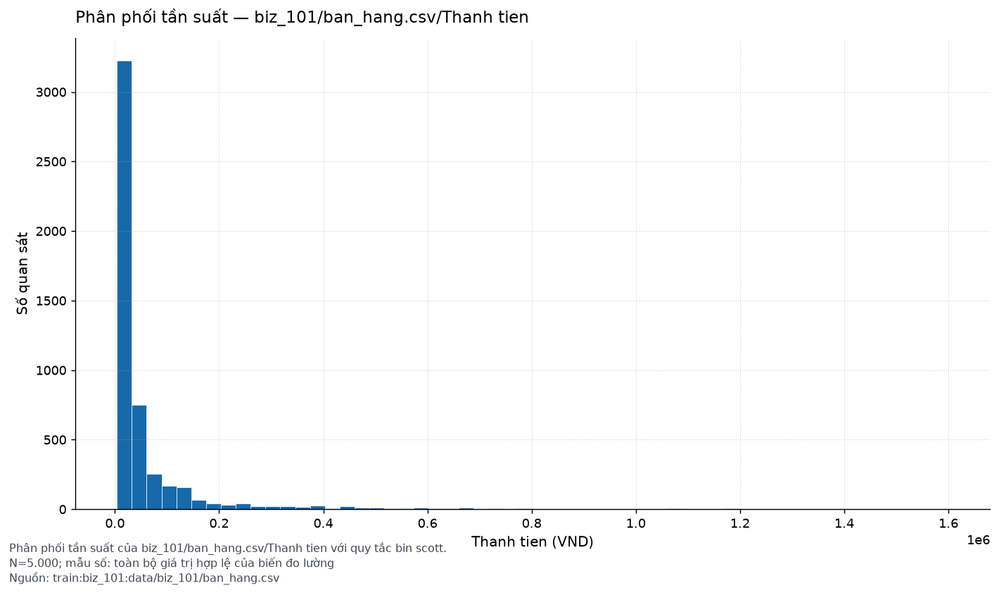
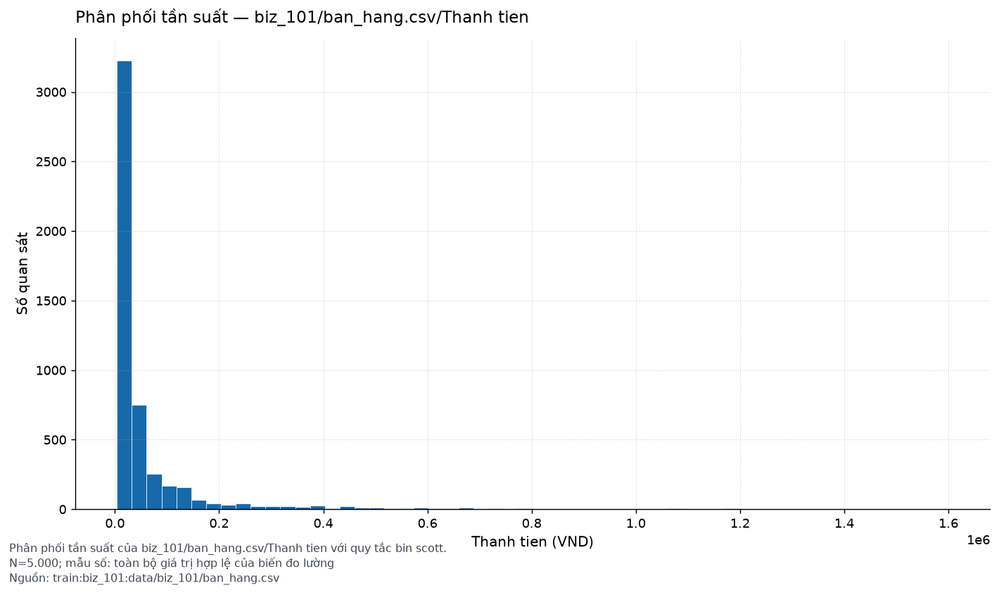


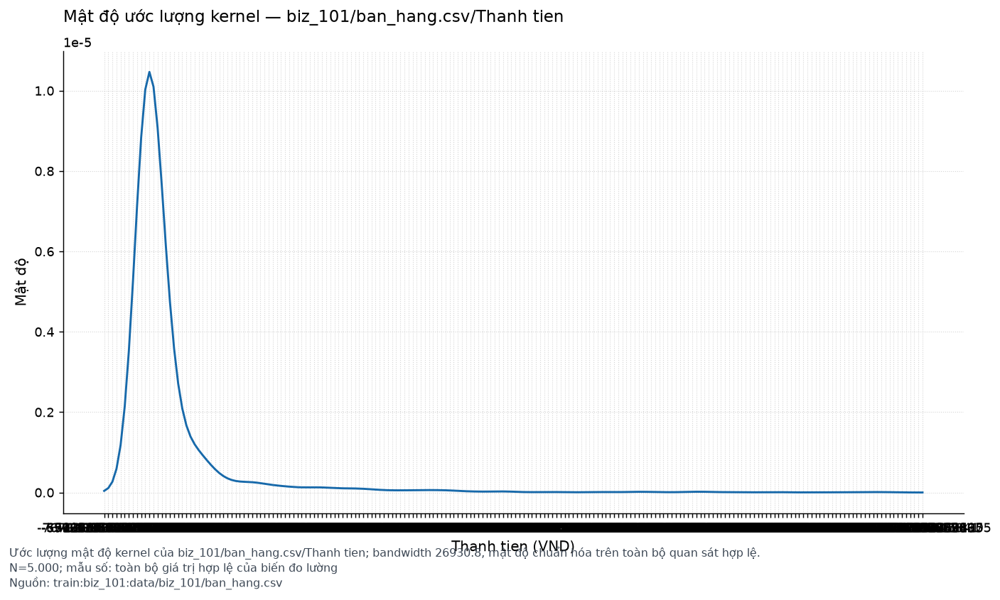


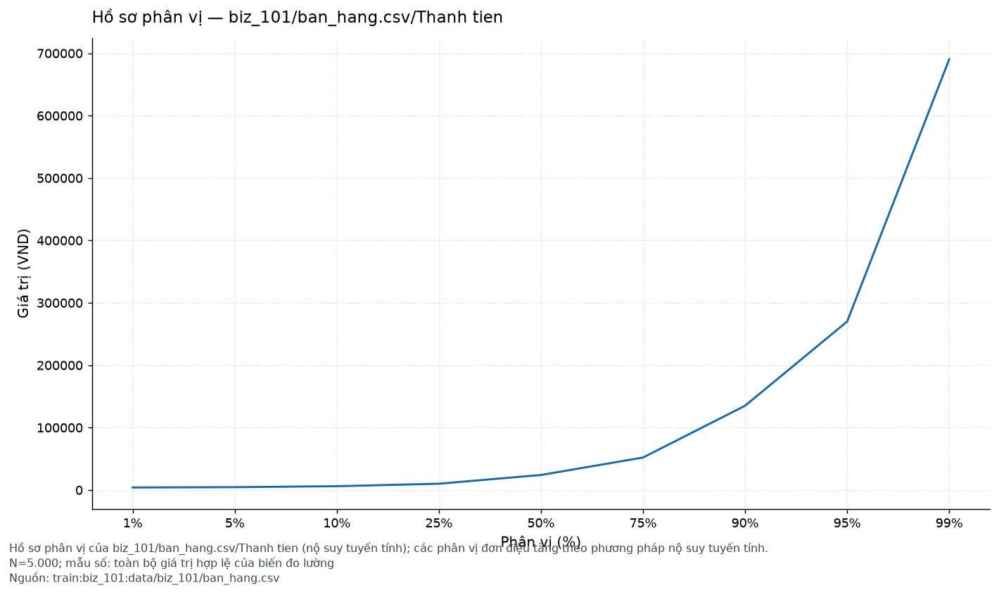


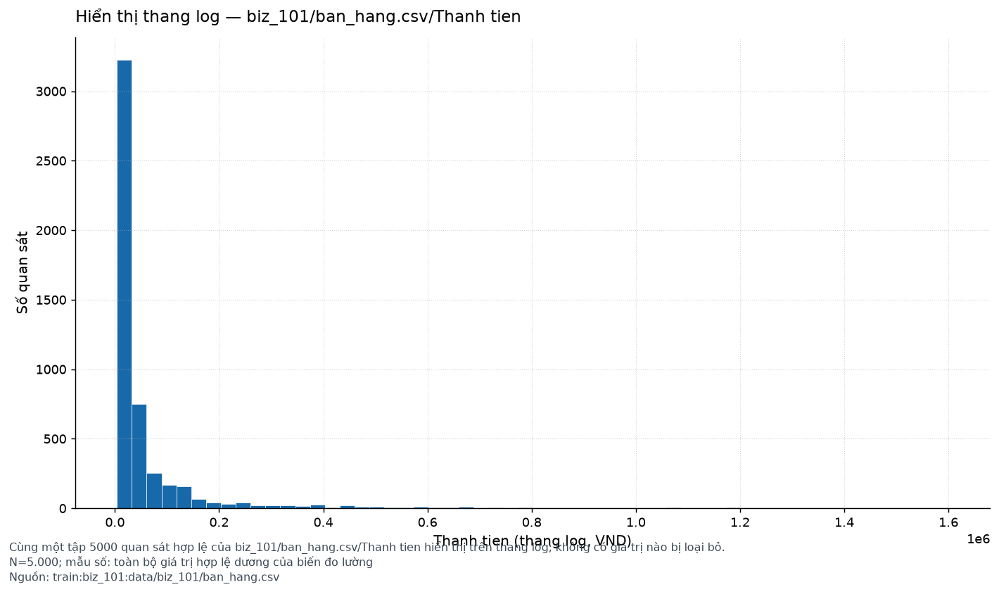

#### Thẻ chuyện `BUS01` — biz_101 (train)

1. **Mục tiêu:** Giá trị đơn hàng phân bố như thế nào?
2. **Bối cảnh:** split = train; doanh nghiệp = biz_101; nguồn = ('train:biz_101:data/biz_101/ban_hang.csv',); đơn vị quan sát = business_id
3. **Phương pháp:** phương pháp = valid_order_amount_distribution; quy tắc lọc = phân phối giá trị đơn hàng hợp lệ; xử lý giá trị khuyết = EXCLUDE_FROM_MEASURE_WITH_COUNT; xử lý ngoại lệ = RETAIN_AND_FLAG
4. **Bảng thống kê:**
   - population_n = 22428
   - n_valid = 22428
   - đơn vị = VND
   - phương pháp = valid_order_amount_distribution
   - công thức = phân phối giá trị đơn hàng hợp lệ
   - lấy mẫu = FULL_AGGREGATION
5. **Biểu đồ:** figures/20261029T155046Z_aa5c21e3/train/biz_101/BUS01.png
6. **Nhận xét:**
   - Trong `biz_101` thuộc split `public_test`, chỉ số `BUS01 — ban_hang.csv` có giá trị `66.000` `VND` trên `22.428` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T01_2025` có giá trị `66.000` `VND` trên `2.711` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T02_2025` có giá trị `65.000` `VND` trên `2.367` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T03_2025` có giá trị `66.000` `VND` trên `1.887` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T04_2025` có giá trị `67.500` `VND` trên `1.769` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T05_2025` có giá trị `65.000` `VND` trên `1.876` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T06_2025` có giá trị `64.500` `VND` trên `1.729` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T07_2025` có giá trị `65.000` `VND` trên `1.848` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T08_2025` có giá trị `68.000` `VND` trên `1.833` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T09_2025` có giá trị `67.000` `VND` trên `1.755` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T10_2025` có giá trị `69.000` `VND` trên `1.869` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T11_2025` có giá trị `74.000` `VND` trên `1.768` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T12_2025` có giá trị `65.000` `VND` trên `1.783` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T01_2026` có giá trị `71.400` `VND` trên `1.870` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T02_2026` có giá trị `68.900` `VND` trên `2.889` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạn

In [9]:
_show_table('TBL09', 'train')

_show_figure('NUM01', 'train', 2)
_show_figure('NUM02', 'train', 1)
_show_figure('NUM06', 'train', 1)
_show_figure('NUM08', 'train', 1)

display(Markdown(run.story_cards_markdown(
    'train'
)[:5200]))


## 06. Phân tích phân loại

**Mục tiêu:** Khảo sát phân phối tần suất của các trường phân loại, giữ nguyên nhóm Others và ghi nhận ứng viên bí danh thay vì tự gộp.

**Phương pháp:** Đếm tần suất theo giá trị đã chuẩn hóa, sắp xếp theo tần suất giảm dần và ghi rõ phạm vi quan sát của mỗi trường.

**Cách đọc và hạn chế:** Cao độ lớp phụ thuộc quy tắc chuẩn hóa giá trị; các giá trị tương tự nhau về nghĩa chỉ được báo cáo là ứng viên, không tự ý hợp nhất.


source_id,field,category,count,share,is_null,business_id,rank
train:biz_101:data/biz_101/ban_hang.csv,Kết quả,Xong,53893,0.953842,false,biz_101,1
train:biz_101:data/biz_101/ban_hang.csv,Kết quả,Đã hủy,1714,0.030336,false,biz_101,2
train:biz_101:data/biz_101/ban_hang.csv,Kết quả,Đổi trả,863,0.015274,false,biz_101,3
train:biz_101:data/biz_101/ban_hang.csv,Kết quả,Đang giao,31,0.000549,false,biz_101,4
train:biz_101:data/biz_101/ban_hang.csv,Nội dung,Mì Hảo Hảo tôm chua cay,2557,0.045256,false,biz_101,1
train:biz_101:data/biz_101/ban_hang.csv,Nội dung,Trứng gà so,1983,0.035097,false,biz_101,2
train:biz_101:data/biz_101/ban_hang.csv,Nội dung,Nước suối Aquafina 500ml,1918,0.033946,false,biz_101,3
train:biz_101:data/biz_101/ban_hang.csv,Nội dung,Sữa tươi Vinamilk 180ml,1760,0.03115,false,biz_101,4
train:biz_101:data/biz_101/ban_hang.csv,Nội dung,Sting dâu 330ml,1697,0.030035,false,biz_101,5
train:biz_101:data/biz_101/ban_hang.csv,Nội dung,Snack Oishi tôm cay 40g,1631,0.028867,false,biz_101,6



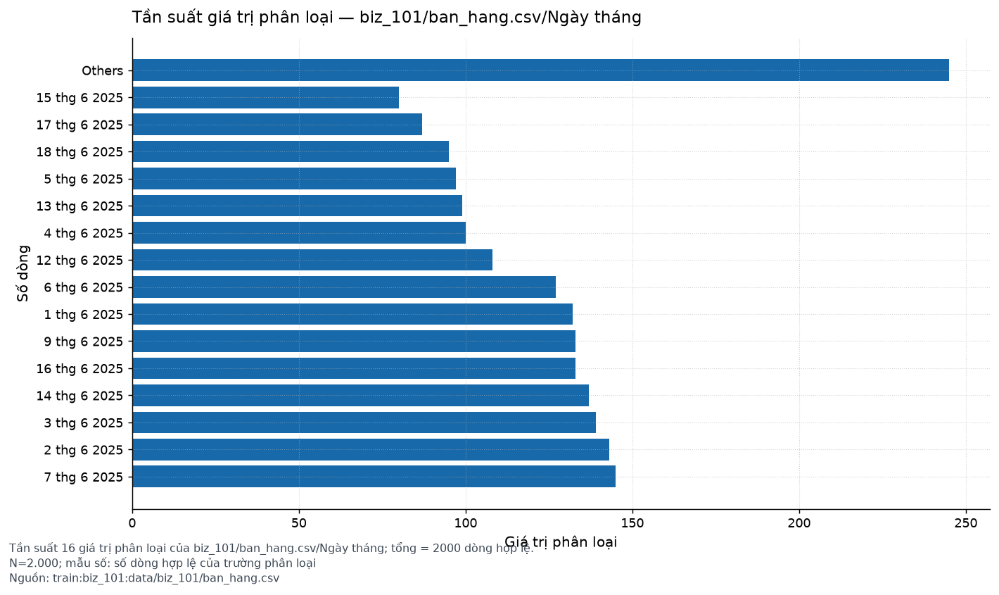
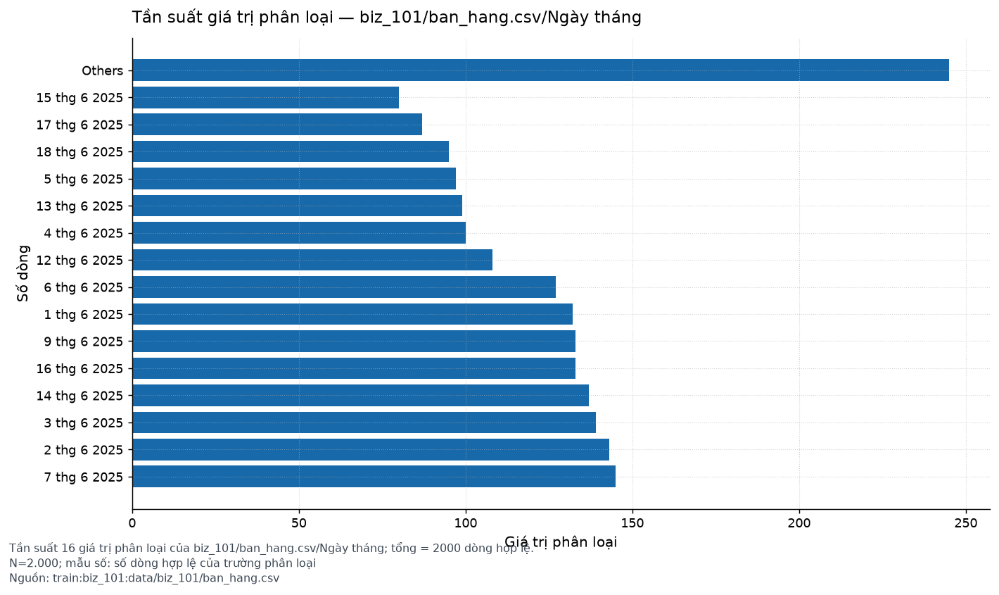


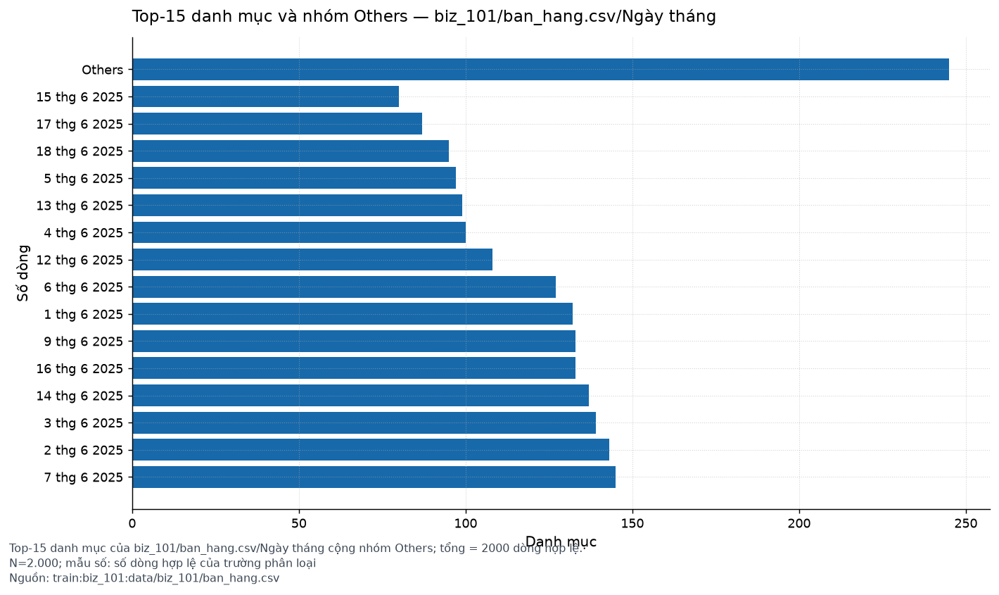


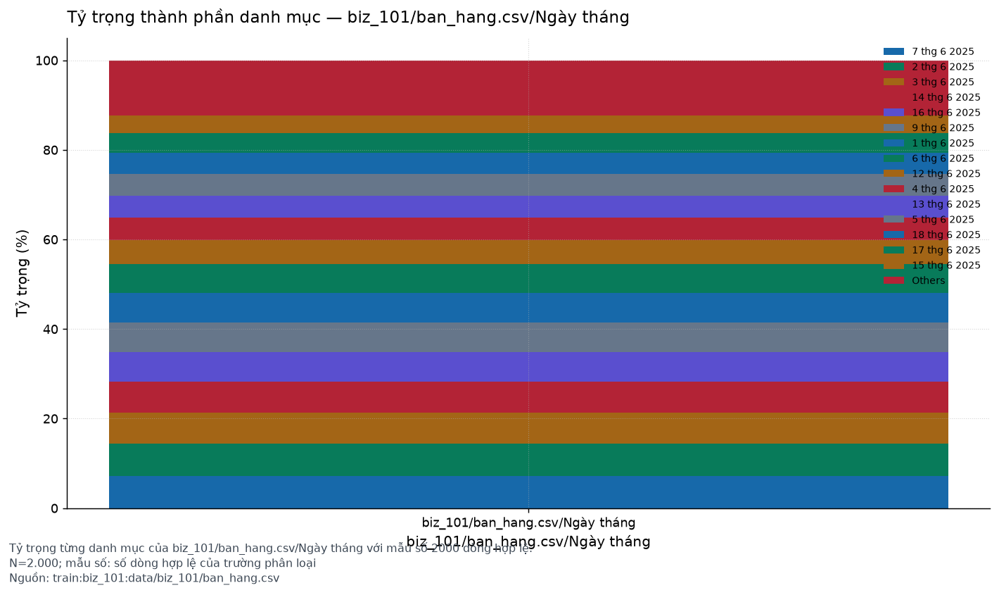

#### Thẻ chuyện `BUS01` — biz_101 (train)

1. **Mục tiêu:** Giá trị đơn hàng phân bố như thế nào?
2. **Bối cảnh:** split = train; doanh nghiệp = biz_101; nguồn = ('train:biz_101:data/biz_101/ban_hang.csv',); đơn vị quan sát = business_id
3. **Phương pháp:** phương pháp = valid_order_amount_distribution; quy tắc lọc = phân phối giá trị đơn hàng hợp lệ; xử lý giá trị khuyết = EXCLUDE_FROM_MEASURE_WITH_COUNT; xử lý ngoại lệ = RETAIN_AND_FLAG
4. **Bảng thống kê:**
   - population_n = 22428
   - n_valid = 22428
   - đơn vị = VND
   - phương pháp = valid_order_amount_distribution
   - công thức = phân phối giá trị đơn hàng hợp lệ
   - lấy mẫu = FULL_AGGREGATION
5. **Biểu đồ:** figures/20261029T155046Z_aa5c21e3/train/biz_101/BUS01.png
6. **Nhận xét:**
   - Trong `biz_101` thuộc split `public_test`, chỉ số `BUS01 — ban_hang.csv` có giá trị `66.000` `VND` trên `22.428` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T01_2025` có giá trị `66.000` `VND` trên `2.711` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T02_2025` có giá trị `65.000` `VND` trên `2.367` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T03_2025` có giá trị `66.000` `VND` trên `1.887` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T04_2025` có giá trị `67.500` `VND` trên `1.769` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T05_2025` có giá trị `65.000` `VND` trên `1.876` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T06_2025` có giá trị `64.500` `VND` trên `1.729` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T07_2025` có giá trị `65.000` `VND` trên `1.848` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T08_2025` có giá trị `68.000` `VND` trên `1.833` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T09_2025` có giá trị `67.000` `VND` trên `1.755` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T10_2025` có giá trị `69.000` `VND` trên `1.869` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T11_2025` có giá trị `74.000` `VND` trên `1.768` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T12_2025` có giá trị `65.000` `VND` trên `1.783` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T01_2026` có giá trị `71.400` `VND` trên `1.870` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T02_2026` có giá trị `68.900` `VND` trên `2.889` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạn

In [10]:
_show_table('TBL10', 'train')

_show_figure('CAT01', 'train', 2)
_show_figure('CAT02', 'train', 1)
_show_figure('CAT03', 'train', 1)

display(Markdown(run.story_cards_markdown(
    'train'
)[:5200]))


## 07. Tương quan và phân tích đa biến

**Mục tiêu:** Đo mức liên hệ giữa các đo lường và các trường phân loại trên cùng grain, chỉ dùng các phép nối đã được phê duyệt.

**Phương pháp:** Tính Pearson, Spearman, Kendall, Cramér V và bảng chéo trong phạm vi cùng một nguồn hoặc phép nối không nhân bản.

**Cách đọc và hạn chế:** Tương quan không phải quan hệ nhân quả; phép nối ứng viên chỉ được hiển thị để đánh giá rủi ro nhân bản, không dùng cho tính chỉ số.


left_source,right_source,join_keys,matched_rows,unmatched_left_rows,duplicate_key_left,fanout_factor,status,relation_id,left_grain,right_grain,unmatched_right_rows,duplicate_key_right,risk
train:biz_102:data/biz_102/DanhSachQuyDoi.xlsx#sheet=Sheet1,train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T01_2025,"Tên sản phẩm, Tên sản phẩm",59,0,18,86.6753,CANDIDATE,train.biz_102.Sheet1__Tên sản phẩm_Tên sản phẩm__T01_2025,one row per Sheet1,one row per T01_2025,1,6614,duplicate_keys_may_cause_fanout
train:biz_102:data/biz_102/DanhSachQuyDoi.xlsx#sheet=Sheet1,train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T02_2025,"Tên sản phẩm, Tên sản phẩm",59,0,18,77.4026,CANDIDATE,train.biz_102.Sheet1__Tên sản phẩm_Tên sản phẩm__T02_2025,one row per Sheet1,one row per T02_2025,1,5900,duplicate_keys_may_cause_fanout
train:biz_102:data/biz_102/DanhSachQuyDoi.xlsx#sheet=Sheet1,train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T03_2025,"Tên sản phẩm, Tên sản phẩm",59,0,18,62.1429,CANDIDATE,train.biz_102.Sheet1__Tên sản phẩm_Tên sản phẩm__T03_2025,one row per Sheet1,one row per T03_2025,1,4725,duplicate_keys_may_cause_fanout
train:biz_102:data/biz_102/DanhSachQuyDoi.xlsx#sheet=Sheet1,train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T04_2025,"Tên sản phẩm, Tên sản phẩm",59,0,18,59.5714,CANDIDATE,train.biz_102.Sheet1__Tên sản phẩm_Tên sản phẩm__T04_2025,one row per Sheet1,one row per T04_2025,1,4527,duplicate_keys_may_cause_fanout
train:biz_102:data/biz_102/DanhSachQuyDoi.xlsx#sheet=Sheet1,train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T05_2025,"Tên sản phẩm, Tên sản phẩm",59,0,18,59.4156,CANDIDATE,train.biz_102.Sheet1__Tên sản phẩm_Tên sản phẩm__T05_2025,one row per Sheet1,one row per T05_2025,1,4515,duplicate_keys_may_cause_fanout
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T01_2025,train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T02_2025,"Mã đơn hàng, Mã đơn hàng",0,2711,3963,0.893,REJECTED,train.biz_102.T01_2025__Mã đơn hàng_Mã đơn hàng__T02_2025,one row per T01_2025,one row per T02_2025,2367,3593,no_key_overlap
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T01_2025,train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T02_2025,"Ngày đặt hàng, Ngày đặt hàng",0,31,6643,0.893,REJECTED,train.biz_102.T01_2025__Ngày đặt hàng_Ngày đặt hàng__T02_2025,one row per T01_2025,one row per T02_2025,28,5932,no_key_overlap
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T01_2025,train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T03_2025,"Mã đơn hàng, Mã đơn hàng",0,2711,3963,0.717,REJECTED,train.biz_102.T01_2025__Mã đơn hàng_Mã đơn hàng__T03_2025,one row per T01_2025,one row per T03_2025,1887,2898,no_key_overlap
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T01_2025,train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T03_2025,"Ngày đặt hàng, Ngày đặt hàng",0,31,6643,0.717,REJECTED,train.biz_102.T01_2025__Ngày đặt hàng_Ngày đặt hàng__T03_2025,one row per T01_2025,one row per T03_2025,31,4754,no_key_overlap
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T01_2025,train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T04_2025,"Mã đơn hàng, Mã đơn hàng",0,2711,3963,0.6873,REJECTED,train.biz_102.T01_2025__Mã đơn hàng_Mã đơn hàng__T04_2025,one row per T01_2025,one row per T04_2025,1769,2818,no_key_overlap



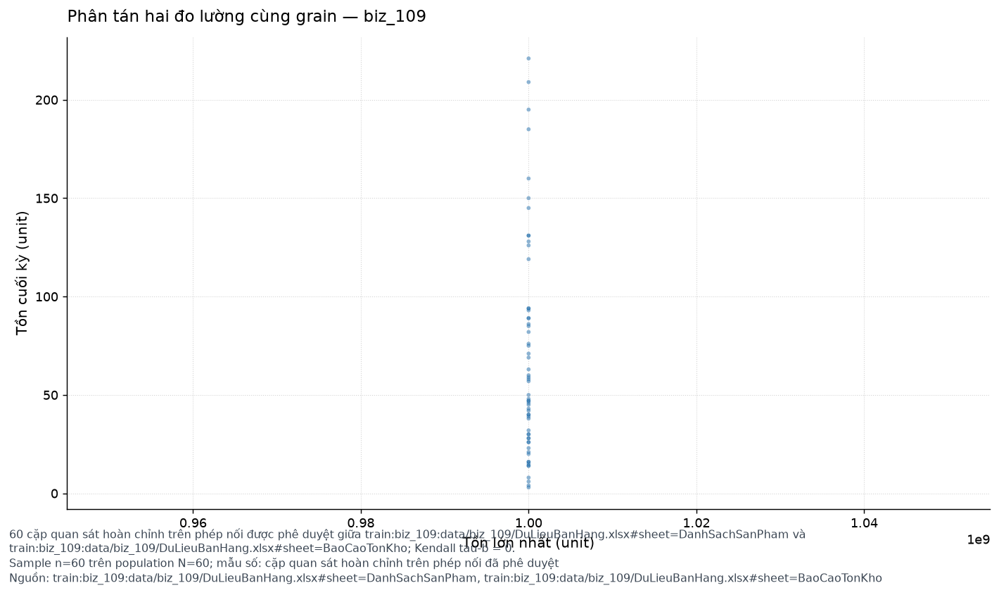


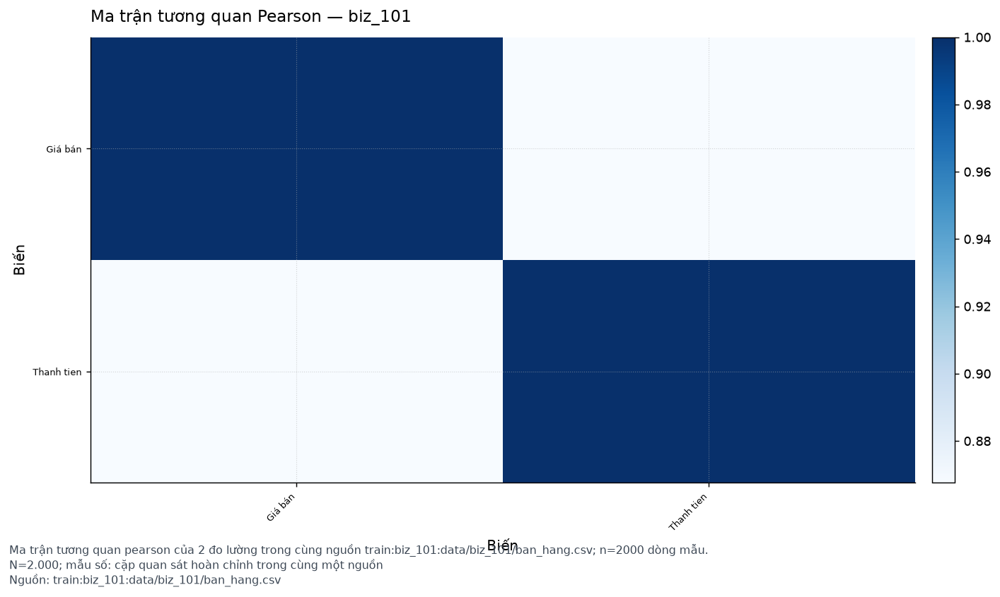


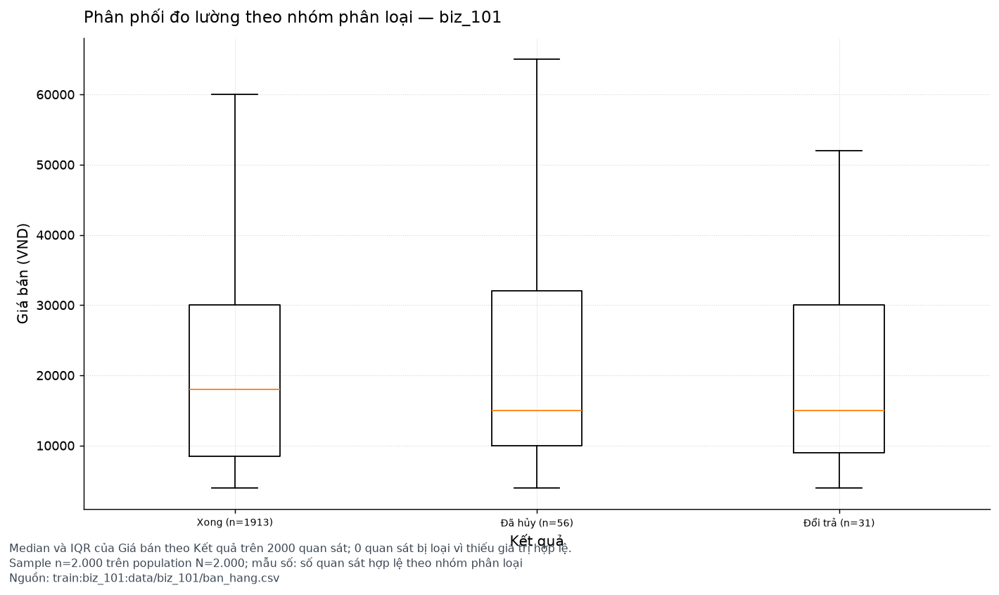


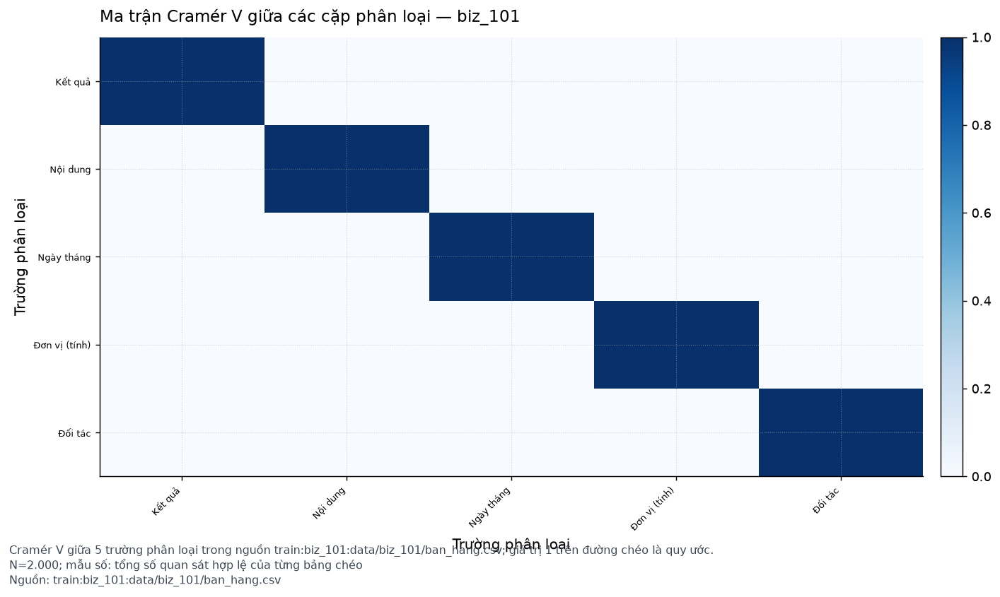


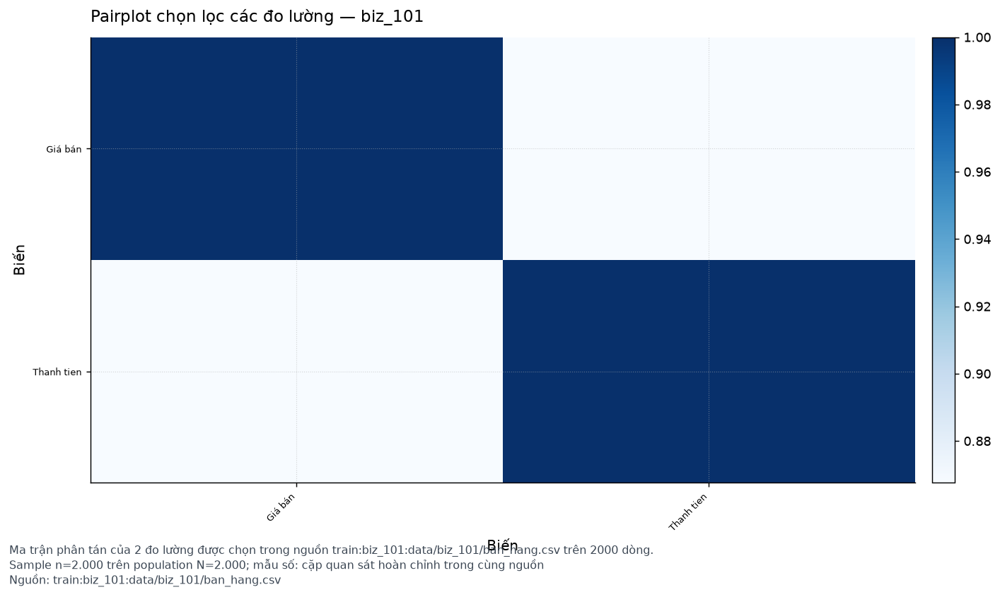


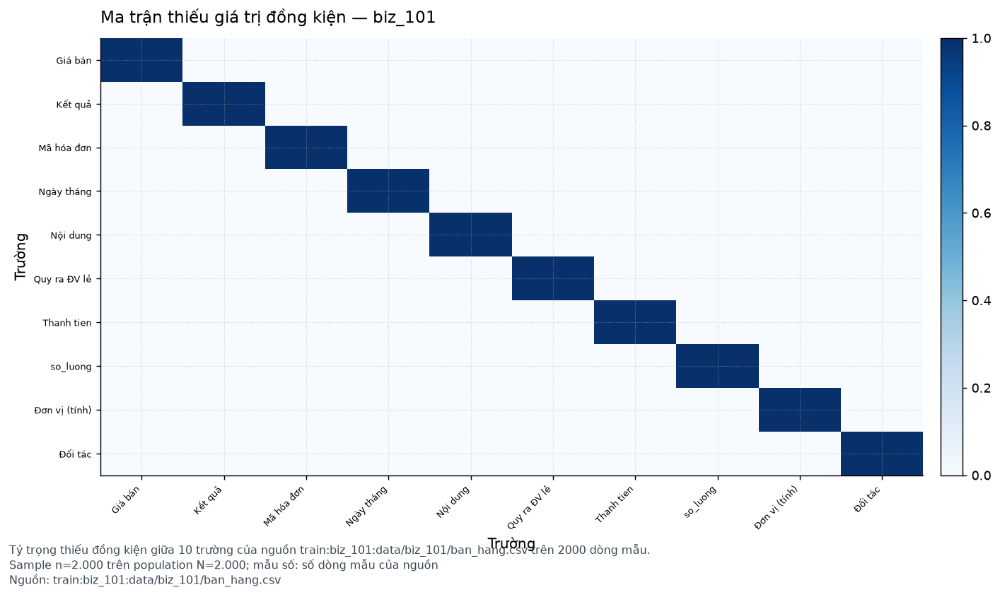

#### Thẻ chuyện `BUS01` — biz_101 (train)

1. **Mục tiêu:** Giá trị đơn hàng phân bố như thế nào?
2. **Bối cảnh:** split = train; doanh nghiệp = biz_101; nguồn = ('train:biz_101:data/biz_101/ban_hang.csv',); đơn vị quan sát = business_id
3. **Phương pháp:** phương pháp = valid_order_amount_distribution; quy tắc lọc = phân phối giá trị đơn hàng hợp lệ; xử lý giá trị khuyết = EXCLUDE_FROM_MEASURE_WITH_COUNT; xử lý ngoại lệ = RETAIN_AND_FLAG
4. **Bảng thống kê:**
   - population_n = 22428
   - n_valid = 22428
   - đơn vị = VND
   - phương pháp = valid_order_amount_distribution
   - công thức = phân phối giá trị đơn hàng hợp lệ
   - lấy mẫu = FULL_AGGREGATION
5. **Biểu đồ:** figures/20261029T155046Z_aa5c21e3/train/biz_101/BUS01.png
6. **Nhận xét:**
   - Trong `biz_101` thuộc split `public_test`, chỉ số `BUS01 — ban_hang.csv` có giá trị `66.000` `VND` trên `22.428` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T01_2025` có giá trị `66.000` `VND` trên `2.711` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T02_2025` có giá trị `65.000` `VND` trên `2.367` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T03_2025` có giá trị `66.000` `VND` trên `1.887` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T04_2025` có giá trị `67.500` `VND` trên `1.769` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T05_2025` có giá trị `65.000` `VND` trên `1.876` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T06_2025` có giá trị `64.500` `VND` trên `1.729` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T07_2025` có giá trị `65.000` `VND` trên `1.848` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T08_2025` có giá trị `68.000` `VND` trên `1.833` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T09_2025` có giá trị `67.000` `VND` trên `1.755` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T10_2025` có giá trị `69.000` `VND` trên `1.869` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T11_2025` có giá trị `74.000` `VND` trên `1.768` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T12_2025` có giá trị `65.000` `VND` trên `1.783` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T01_2026` có giá trị `71.400` `VND` trên `1.870` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T02_2026` có giá trị `68.900` `VND` trên `2.889` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạn

In [11]:
_show_table('TBL12', 'train')

_show_figure('REL01', 'train', 1)
_show_figure('REL03', 'train', 1)
_show_figure('REL06', 'train', 1)
_show_figure('REL07', 'train', 1)
_show_figure('REL08', 'train', 1)
_show_figure('REL09', 'train', 1)
_show_figure('REL10', 'train', 1)

display(Markdown(run.story_cards_markdown(
    'train'
)[:5200]))


## 08. Hồ sơ thời gian và lịch

**Mục tiêu:** Xác định ngữ nghĩa trường ngày, khoảng phủ thời gian, số ngày có hoạt động và các kỳ bị thiếu theo lịch của split.

**Phương pháp:** Đọc và chuẩn hóa giá trị ngày theo quy tắc từng split, đối chiếu với lịch và báo cáo khoảng phủ theo doanh nghiệp.

**Cách đọc và hạn chế:** Mỗi trường ngày giữ vai trò sự kiện riêng nên các khoảng phủ không thể so sánh trực tiếp; thiếu dữ liệu theo kỳ không được coi là giá trị bằng không.


source_id,column,event_role,min_date,max_date,active_days,missing_months,business_id,valid_n,parse_failure_n,distinct_dates,span_days,coverage_ratio,status
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T01_2025,Ngày đặt hàng,order,2025-01-01,2025-01-31,31,none,biz_102,6674,0,31,31,1,PASS
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T02_2025,Ngày đặt hàng,order,2025-02-01,2025-02-28,28,none,biz_102,5960,0,28,28,1,PASS
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T03_2025,Ngày đặt hàng,order,2025-03-01,2025-03-31,31,none,biz_102,4785,0,31,31,1,PASS
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T04_2025,Ngày đặt hàng,order,2025-04-01,2025-04-30,30,none,biz_102,4587,0,30,30,1,PASS
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T05_2025,Ngày đặt hàng,order,2025-05-01,2025-05-31,31,none,biz_102,4575,0,31,31,1,PASS
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T06_2025,Ngày đặt hàng,order,2025-06-01,2025-06-30,30,none,biz_102,4287,0,30,30,1,PASS
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T07_2025,Ngày đặt hàng,order,2025-07-01,2025-07-31,31,none,biz_102,4568,0,31,31,1,PASS
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T08_2025,Ngày đặt hàng,order,2025-08-01,2025-08-31,31,none,biz_102,4626,0,31,31,1,PASS
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T09_2025,Ngày đặt hàng,order,2025-09-01,2025-09-30,30,none,biz_102,4410,0,30,30,1,PASS
train:biz_102:data/biz_102/DonHang_ChiTiet.xlsx#sheet=T10_2025,Ngày đặt hàng,order,2025-10-01,2025-10-31,31,none,biz_102,4715,0,31,31,1,PASS



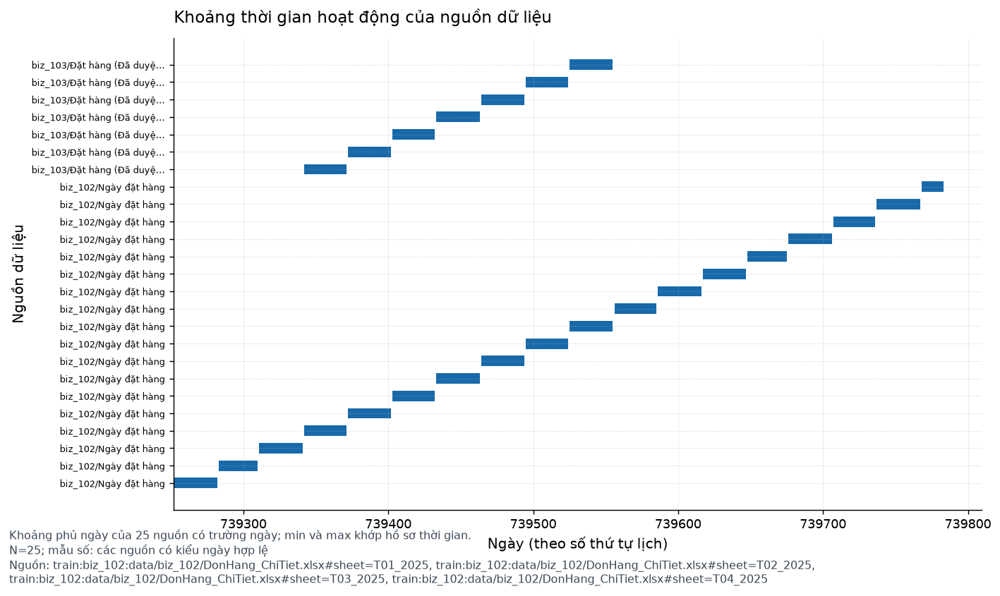


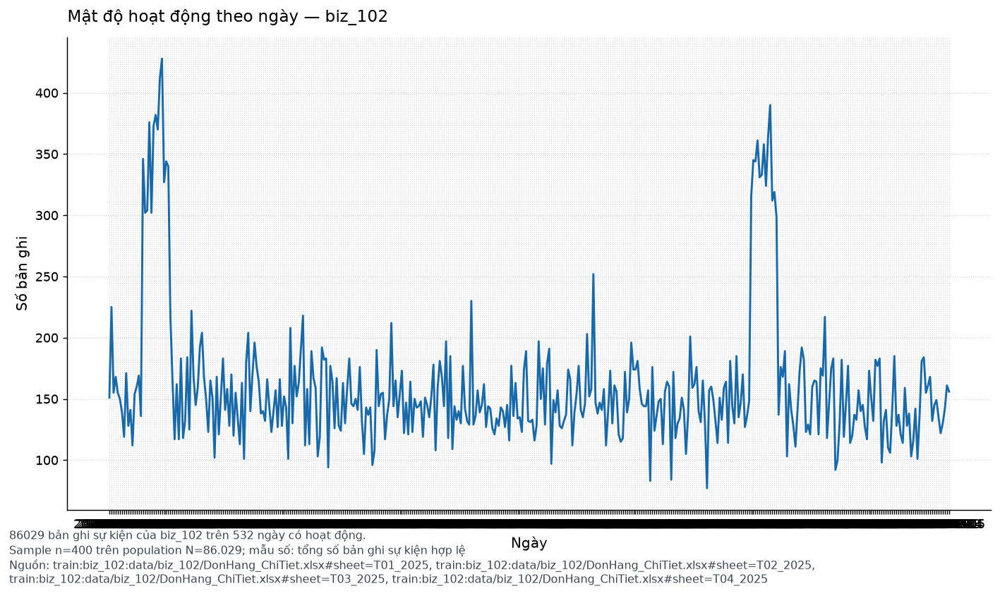


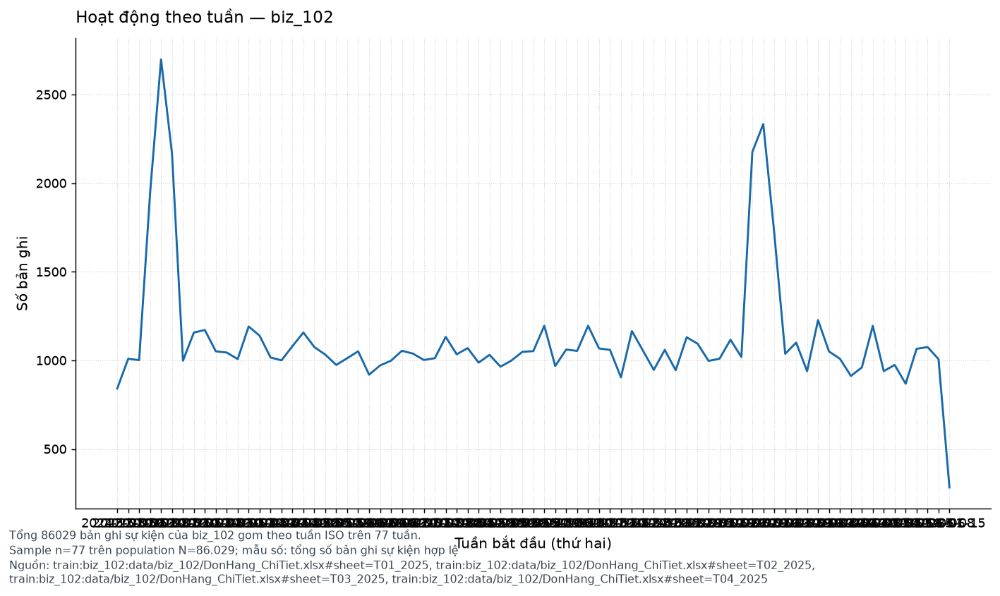


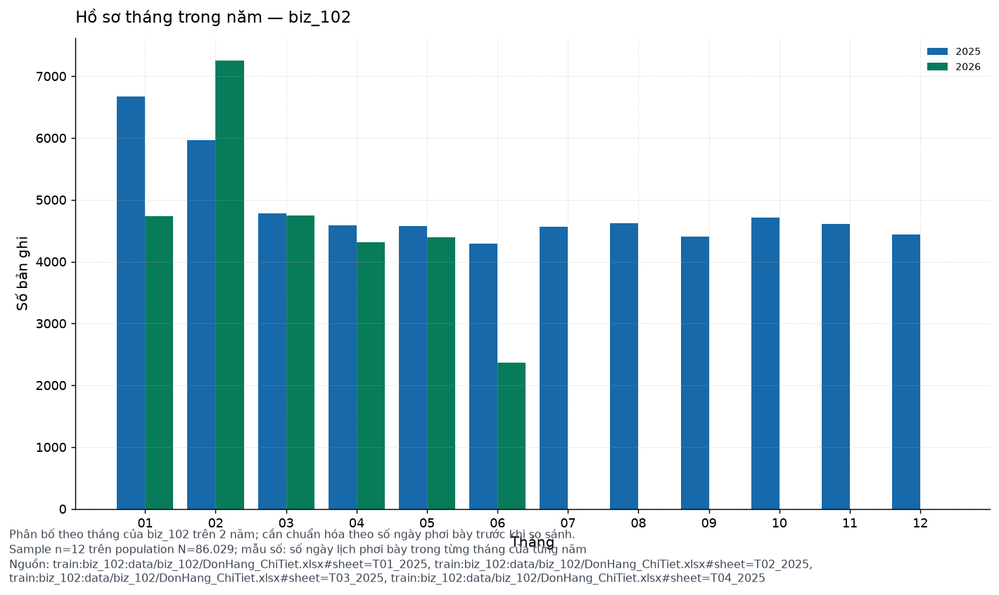

#### Thẻ chuyện `BUS01` — biz_101 (train)

1. **Mục tiêu:** Giá trị đơn hàng phân bố như thế nào?
2. **Bối cảnh:** split = train; doanh nghiệp = biz_101; nguồn = ('train:biz_101:data/biz_101/ban_hang.csv',); đơn vị quan sát = business_id
3. **Phương pháp:** phương pháp = valid_order_amount_distribution; quy tắc lọc = phân phối giá trị đơn hàng hợp lệ; xử lý giá trị khuyết = EXCLUDE_FROM_MEASURE_WITH_COUNT; xử lý ngoại lệ = RETAIN_AND_FLAG
4. **Bảng thống kê:**
   - population_n = 22428
   - n_valid = 22428
   - đơn vị = VND
   - phương pháp = valid_order_amount_distribution
   - công thức = phân phối giá trị đơn hàng hợp lệ
   - lấy mẫu = FULL_AGGREGATION
5. **Biểu đồ:** figures/20261029T155046Z_aa5c21e3/train/biz_101/BUS01.png
6. **Nhận xét:**
   - Trong `biz_101` thuộc split `public_test`, chỉ số `BUS01 — ban_hang.csv` có giá trị `66.000` `VND` trên `22.428` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T01_2025` có giá trị `66.000` `VND` trên `2.711` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T02_2025` có giá trị `65.000` `VND` trên `2.367` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T03_2025` có giá trị `66.000` `VND` trên `1.887` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T04_2025` có giá trị `67.500` `VND` trên `1.769` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T05_2025` có giá trị `65.000` `VND` trên `1.876` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T06_2025` có giá trị `64.500` `VND` trên `1.729` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T07_2025` có giá trị `65.000` `VND` trên `1.848` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T08_2025` có giá trị `68.000` `VND` trên `1.833` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T09_2025` có giá trị `67.000` `VND` trên `1.755` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T10_2025` có giá trị `69.000` `VND` trên `1.869` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T11_2025` có giá trị `74.000` `VND` trên `1.768` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T12_2025` có giá trị `65.000` `VND` trên `1.783` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T01_2026` có giá trị `71.400` `VND` trên `1.870` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T02_2026` có giá trị `68.900` `VND` trên `2.889` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạn

In [12]:
_show_table('TBL11', 'train')

_show_figure('TIME01', 'train', 1)
_show_figure('TIME02', 'train', 1)
_show_figure('TIME03', 'train', 1)
_show_figure('TIME07', 'train', 1)

display(Markdown(run.story_cards_markdown(
    'train'
)[:5200]))


## 09. Phân tích theo từng doanh nghiệp

**Mục tiêu:** Trình bày hồ sơ, phân loại ngành và các chỉ số kinh doanh đủ điều kiện của từng doanh nghiệp trong split.

**Phương pháp:** Chỉ số được tính trên grain đã xác định, tuân thủ quy tắc trạng thái của rulebook split và chỉ hiển thị khi doanh nghiệp đủ điều kiện.

**Cách đọc và hạn chế:** Doanh nghiệp thiếu điều kiện bị ghi trạng thái rõ ràng, không được thay bằng số liệu của doanh nghiệp khác để lấp chỗ trống.


business_id,split,source_count,readme_present,domain_evidence,status,readme_hash,findings
biz_101,train,1,true,retail_pos,PASS,sha256:c71cf95a70eb10d08546bbf7755d55509d6410e009119579c4528720dadb125a,0
biz_102,train,2,true,retail_grocery,PASS,sha256:6d857ce98b60e60a31147247c7339a5d9ac935987da3042faa14fb4022e04551,70
biz_103,train,2,true,retail_grocery,PASS,sha256:2dcc4d7968fd2d7b74bf4ee2aae5f2bfca9dbdac69346148325e2ae8d82b3622,134
biz_104,train,2,true,retail_grocery,PASS,sha256:70955b88b93c4d4d4b5de1806ed212a9599b9cf9fb959afdc3a042c301af3ab2,10
biz_105,train,6,true,retail_pos,PASS,sha256:a73db6b16c8768c2fca49d10e6e8dcb6cc1054881c63c8afcbef487ae025a326,196
biz_106,train,10,true,retail_grocery,PASS,sha256:f9a2ed4a39f784cc16180f013a2f56ae44b7aab33e5fbaa4899af8c54bbb3515,65
biz_107,train,1,true,retail_pos,PASS,sha256:8f1bb9e115bffdad77e112e42642ec86ab806af7f13bcfdb24dfcfa5e8c964df,7
biz_108,train,7,true,retail_grocery,PASS,sha256:47a853ffb79a0449190a5e331b209977a3a4b323943521c0d28037d01397e9c9,44
biz_109,train,2,true,retail_grocery,PASS,sha256:77fad305fc6460c804107b5d928570d1c3abf4d1cd3c0e5a27a3053fb5f3c0d3,40
biz_110,train,1,true,retail_pos,PASS,sha256:85a5aecce97f14d3841cb259d375962131b0b04d1e6b009c343c39c3dcde265f,3


metric_id,name,grain,rule_id,unit,formula_status,business_id,status_handling,null_behavior
train.biz_101.revenue,revenue,document,train.1_n_h_ng_v_doanh_thu.n_t_nh_v_o_doanh_thu,VND,PASS,biz_101,per split rulebook status policy,excluded from denominator and reported
train.biz_101.order_count,order count,document,train.1_n_h_ng_v_doanh_thu.s_n,count,PASS,biz_101,per split rulebook status policy,excluded from denominator and reported
train.biz_101.quantity_sold,quantity sold,document,train.3_x_p_h_ng.b_n_ch_y,count,BLOCKED,biz_101,per split rulebook status policy,excluded from denominator and reported
train.biz_101.debt_balance,debt balance,document,train.2_th_i_gian.n_h_t_ng_y_x_t_nh_n_h_m_nay,count,BLOCKED,biz_101,per split rulebook status policy,excluded from denominator and reported
train.biz_101.inventory_balance,inventory balance,document,train.5_kho_nh_p_h_ng_gi_v_n.gi_tr_h_ng_t_n_kho,count,BLOCKED,biz_101,per split rulebook status policy,excluded from denominator and reported
train.biz_101.gross_profit,gross profit,document,train.3_x_p_h_ng.h_ng_l_i_nh_t,count,BLOCKED,biz_101,per split rulebook status policy,excluded from denominator and reported
train.biz_101.purchase_value,purchase value,document,train.5_kho_nh_p_h_ng_gi_v_n.ti_n_nh_p_h_ng_trong_k,count,BLOCKED,biz_101,per split rulebook status policy,excluded from denominator and reported
train.biz_101.customer_ranking,customer ranking,document,train.3_x_p_h_ng.x_c_nh_kh_ch,count,BLOCKED,biz_101,per split rulebook status policy,excluded from denominator and reported
train.biz_101.employee_ranking,employee ranking,document,train.3_x_p_h_ng.nh_n_vi_n_b_n_gi_i_nh_t,count,BLOCKED,biz_101,per split rulebook status policy,excluded from denominator and reported
train.biz_101.item_ranking,item ranking,document,train.1_n_h_ng_v_doanh_thu.s_n,count,BLOCKED,biz_101,per split rulebook status policy,excluded from denominator and reported



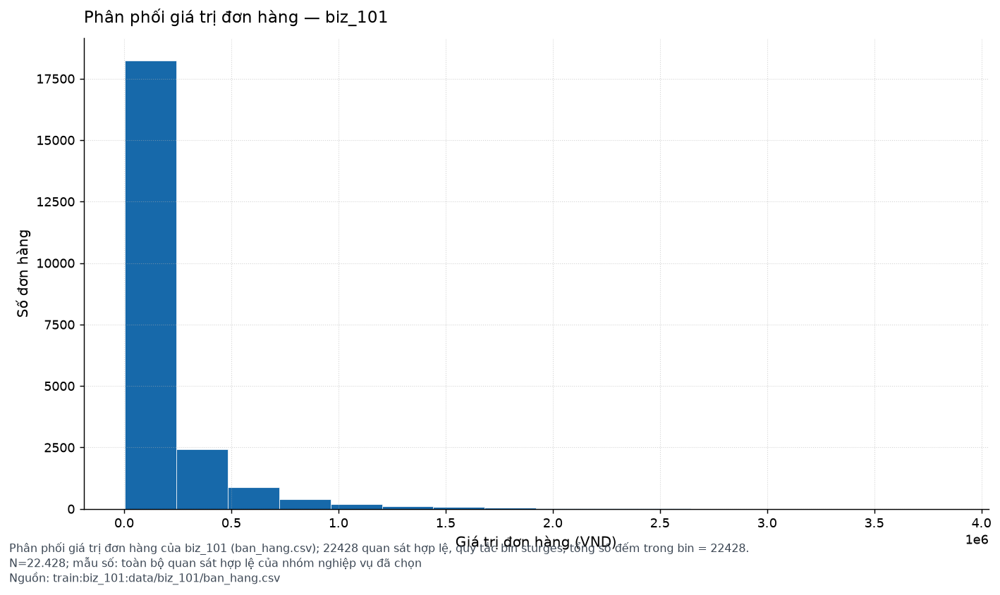
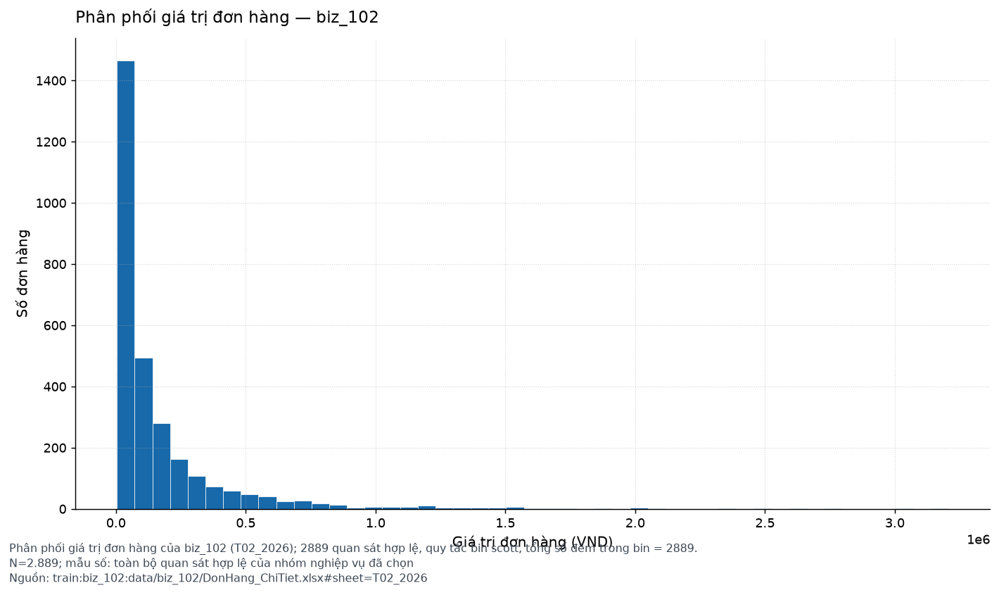


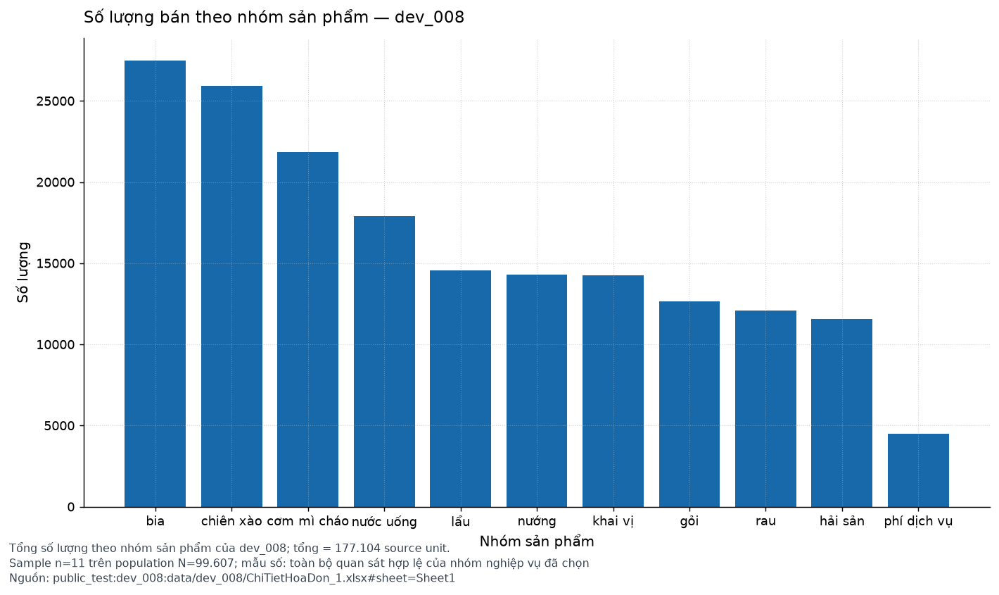


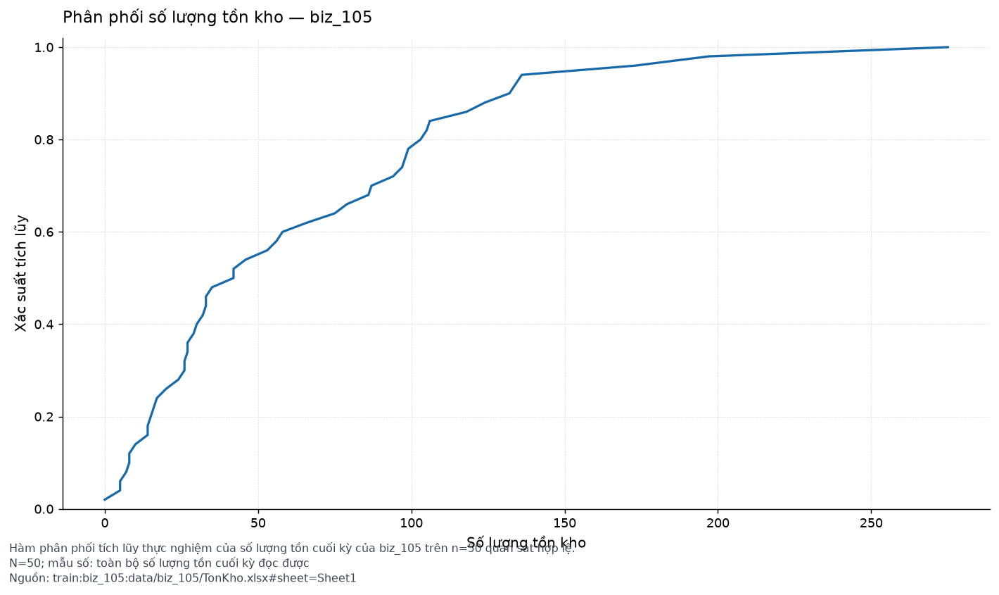


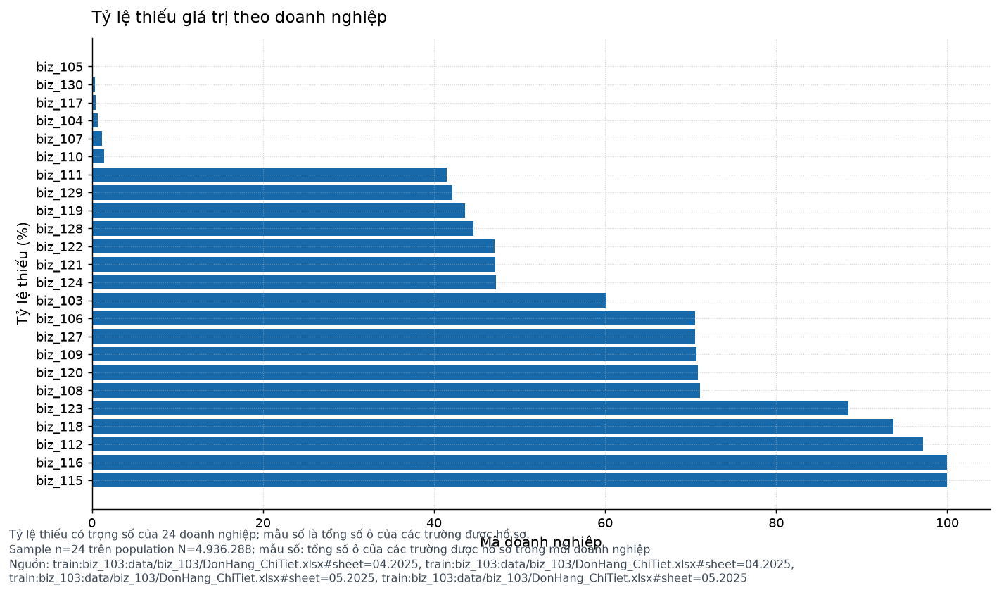

#### Thẻ chuyện `BUS01` — biz_101 (train)

1. **Mục tiêu:** Giá trị đơn hàng phân bố như thế nào?
2. **Bối cảnh:** split = train; doanh nghiệp = biz_101; nguồn = ('train:biz_101:data/biz_101/ban_hang.csv',); đơn vị quan sát = business_id
3. **Phương pháp:** phương pháp = valid_order_amount_distribution; quy tắc lọc = phân phối giá trị đơn hàng hợp lệ; xử lý giá trị khuyết = EXCLUDE_FROM_MEASURE_WITH_COUNT; xử lý ngoại lệ = RETAIN_AND_FLAG
4. **Bảng thống kê:**
   - population_n = 22428
   - n_valid = 22428
   - đơn vị = VND
   - phương pháp = valid_order_amount_distribution
   - công thức = phân phối giá trị đơn hàng hợp lệ
   - lấy mẫu = FULL_AGGREGATION
5. **Biểu đồ:** figures/20261029T155046Z_aa5c21e3/train/biz_101/BUS01.png
6. **Nhận xét:**
   - Trong `biz_101` thuộc split `public_test`, chỉ số `BUS01 — ban_hang.csv` có giá trị `66.000` `VND` trên `22.428` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T01_2025` có giá trị `66.000` `VND` trên `2.711` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T02_2025` có giá trị `65.000` `VND` trên `2.367` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T03_2025` có giá trị `66.000` `VND` trên `1.887` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T04_2025` có giá trị `67.500` `VND` trên `1.769` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T05_2025` có giá trị `65.000` `VND` trên `1.876` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T06_2025` có giá trị `64.500` `VND` trên `1.729` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T07_2025` có giá trị `65.000` `VND` trên `1.848` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T08_2025` có giá trị `68.000` `VND` trên `1.833` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T09_2025` có giá trị `67.000` `VND` trên `1.755` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T10_2025` có giá trị `69.000` `VND` trên `1.869` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T11_2025` có giá trị `74.000` `VND` trên `1.768` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T12_2025` có giá trị `65.000` `VND` trên `1.783` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T01_2026` có giá trị `71.400` `VND` trên `1.870` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T02_2026` có giá trị `68.900` `VND` trên `2.889` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạn

In [13]:
_show_table('TBL13', 'train')
_show_table('TBL14', 'train')

_show_figure('BUS01', 'train', 2)
_show_figure('BUS03', 'train', 1)
_show_figure('BUS05', 'train', 1)
_show_figure('QUAL03', 'train', 1)

display(Markdown(run.story_cards_markdown(
    'train'
)[:5200]))


## 10. Câu hỏi và đáp án tham chiếu Train

**Mục tiêu:** Khảo sát siêu dữ liệu câu hỏi Train và cấu trúc tổng hợp của đáp án tham chiếu mà không trích xuất nội dung đáp án.

**Phương pháp:** Đặc trưng câu hỏi suy ra bằng luật văn phong; đáp án chỉ được đọc ở dạng siêu dữ liệu tổng hợp kiểu và hình dạng cấu trúc.

**Cách đọc và hạn chế:** Nhãn ý định là quy tắc suy ra, không phải chú thích của con người; không có bảng tra cứu đáp án theo mã câu hỏi.


split,question_count,unique_id_count,as_of_min,as_of_max,status,duplicate_id_count,as_of_missing_count,label_access
train,3000,3000,2025-01-15,2026-09-20,PASS,0,0,train_reference_available



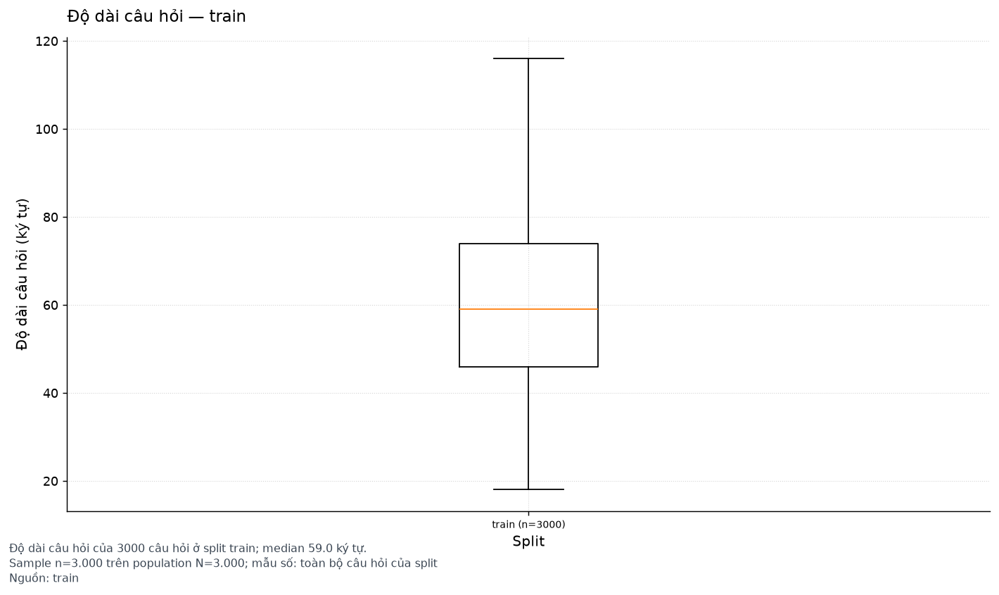


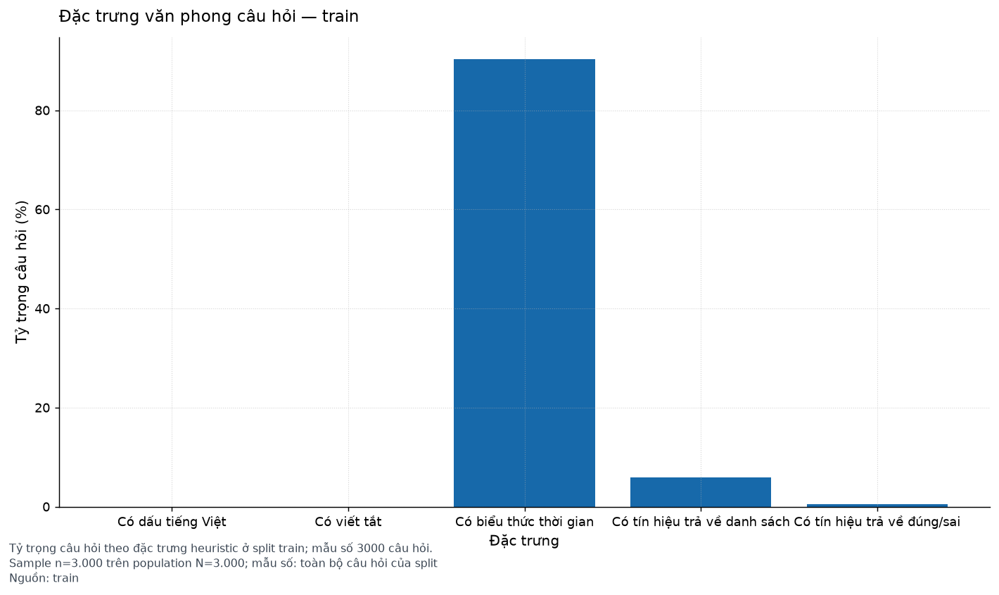


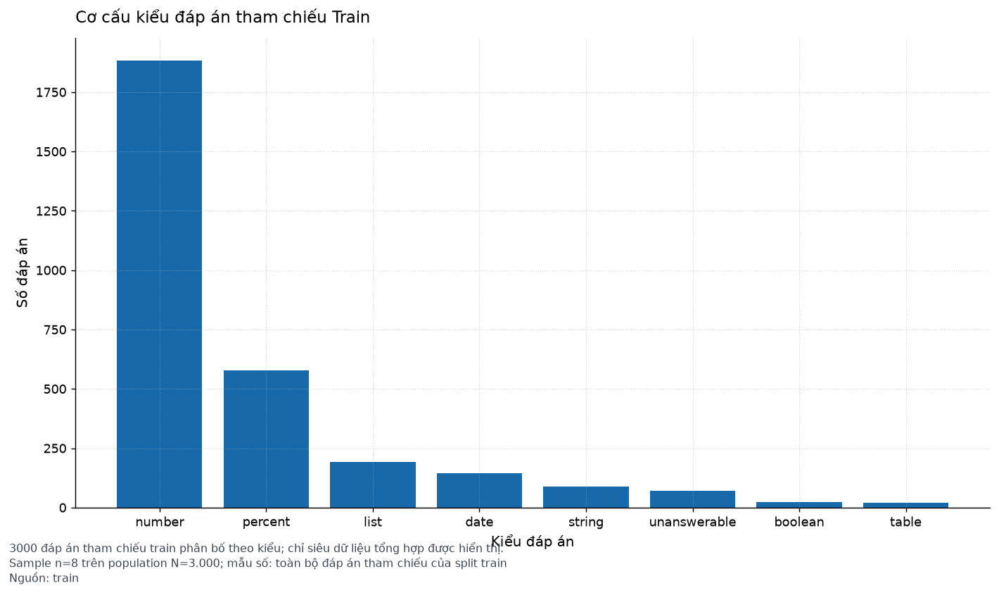


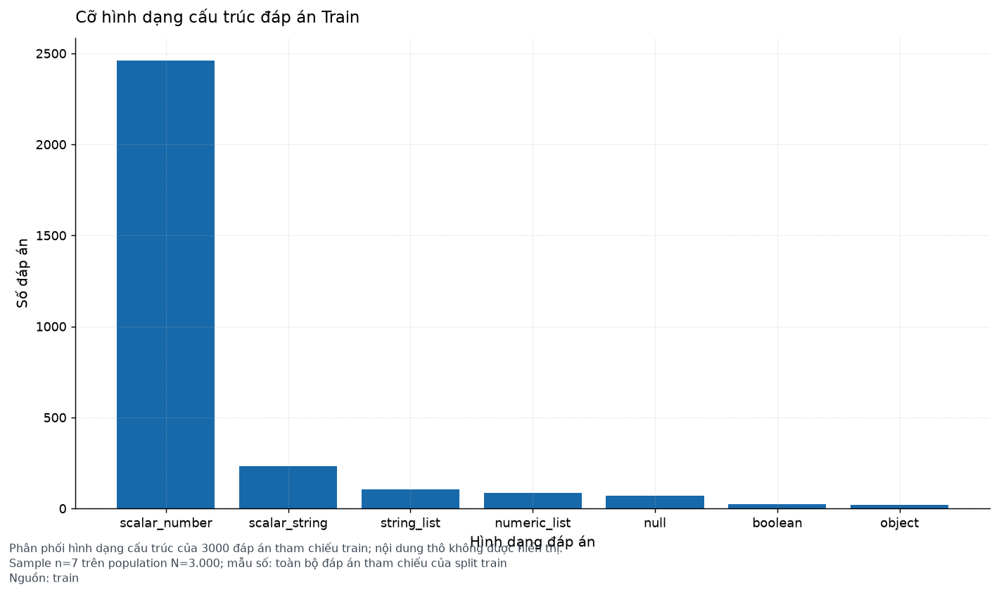

#### Thẻ chuyện `BUS01` — biz_101 (train)

1. **Mục tiêu:** Giá trị đơn hàng phân bố như thế nào?
2. **Bối cảnh:** split = train; doanh nghiệp = biz_101; nguồn = ('train:biz_101:data/biz_101/ban_hang.csv',); đơn vị quan sát = business_id
3. **Phương pháp:** phương pháp = valid_order_amount_distribution; quy tắc lọc = phân phối giá trị đơn hàng hợp lệ; xử lý giá trị khuyết = EXCLUDE_FROM_MEASURE_WITH_COUNT; xử lý ngoại lệ = RETAIN_AND_FLAG
4. **Bảng thống kê:**
   - population_n = 22428
   - n_valid = 22428
   - đơn vị = VND
   - phương pháp = valid_order_amount_distribution
   - công thức = phân phối giá trị đơn hàng hợp lệ
   - lấy mẫu = FULL_AGGREGATION
5. **Biểu đồ:** figures/20261029T155046Z_aa5c21e3/train/biz_101/BUS01.png
6. **Nhận xét:**
   - Trong `biz_101` thuộc split `public_test`, chỉ số `BUS01 — ban_hang.csv` có giá trị `66.000` `VND` trên `22.428` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T01_2025` có giá trị `66.000` `VND` trên `2.711` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T02_2025` có giá trị `65.000` `VND` trên `2.367` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T03_2025` có giá trị `66.000` `VND` trên `1.887` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T04_2025` có giá trị `67.500` `VND` trên `1.769` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T05_2025` có giá trị `65.000` `VND` trên `1.876` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public

In [14]:
_show_table('TBL15', 'train')

_show_figure('QNA01', 'train', 1)
_show_figure('QNA02', 'train', 1)
_show_figure('QNA04', 'train', 1)
_show_figure('QNA05', 'train', 1)

display(Markdown(run.story_cards_markdown(
    'train'
)[:2600]))


## 11. Câu hỏi Public Test và đối chiếu đặc trưng

**Mục tiêu:** Trình bày siêu dữ liệu câu hỏi Public Test và so sánh đặc trưng câu hỏi giữa hai split trên cùng cách chuẩn hóa.

**Phương pháp:** Chỉ đọc tệp câu hỏi của Public Test; tỷ trọng đặc trưng được chuẩn hóa theo số câu hỏi của từng split.

**Cách đọc và hạn chế:** Split Public Test không có đáp án tham chiếu và không được truy cập, suy diễn hay dựng nhãn; mọi so sánh chỉ dựa trên siêu dữ liệu câu hỏi.


split,question_count,unique_id_count,as_of_min,as_of_max,status,duplicate_id_count,as_of_missing_count,label_access
public_test,1000,1000,2025-02-04,2026-09-30,PASS,0,0,no_labels_for_split



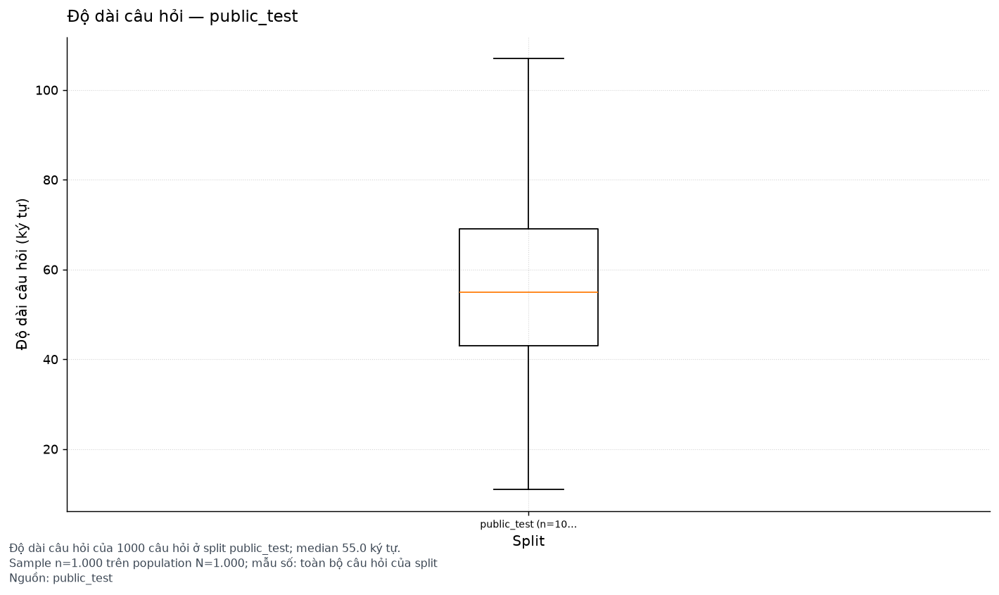


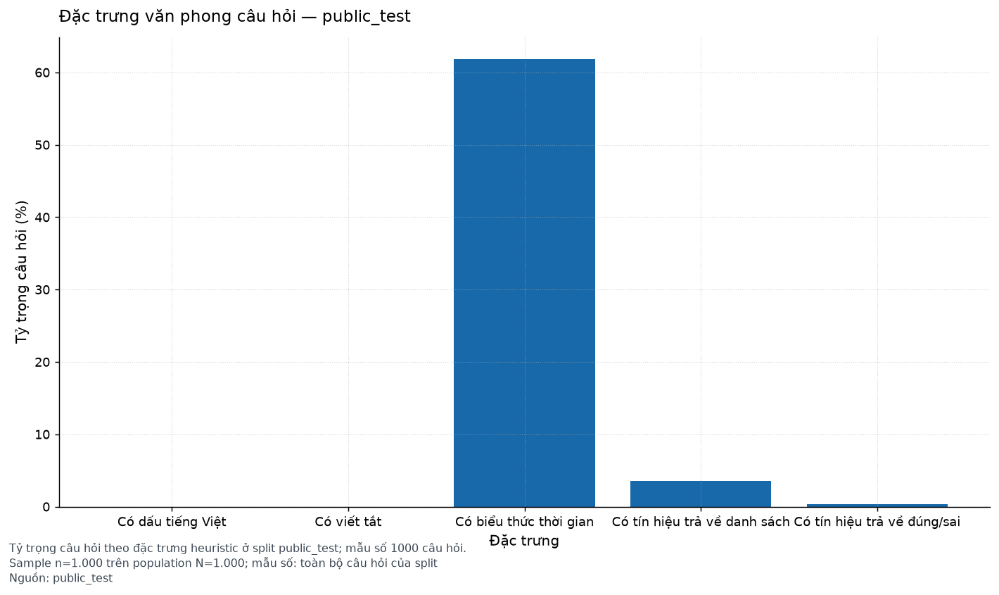


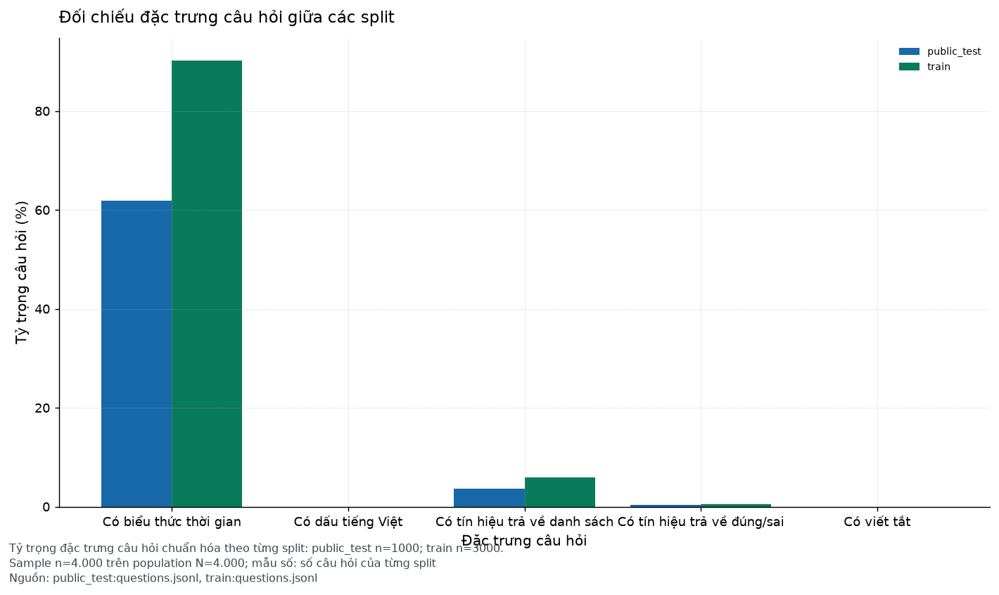

In [15]:
_show_table('TBL15', 'public_test')

_show_figure('QNA01', 'public_test', 1)
_show_figure('QNA02', 'public_test', 1)
_show_figure('QNA07', None, 1)

display(Markdown(run.story_cards_markdown(
    'public_test'
)[:2600]))


## 12. Đối chiếu rulebook giữa hai split

**Mục tiêu:** Nêu chính xác các khác biệt ở cấp quy tắc giữa rulebook Train và Public Test.

**Phương pháp:** So khớp rulebook theo mức quy tắc và phân loại quy tắc chỉ có ở một split hoặc đã bị sửa đổi.

**Cách đọc và hạn chế:** Quy tắc riêng của từng split không được áp dụng chéo; khác biệt rulebook là lý do không thể giả định chỉ số KPI giống nhau giữa hai split.


In [16]:
_show_table('TBL16')


conflict_id,section,train_rule_id,public_rule_id,conflict_status,kind,train_text,public_text
train.only.Giá nhập bình quân một mặt hàng trong tháng,"5. Kho, nhập hàng, giá vốn",train.5_kho_nh_p_h_ng_gi_v_n.gi_nh_p_b_nh_qu_n_m_t_m_t_h_ng_trong_th_ng,none,TRAIN_ONLY,removed_in_public,"bình quân **theo số lượng nhập**, **không** phải trung bình cộng các mức giá nhập; theo đơn vị nhập, các phiếu có ngày phiếu trong tháng, bỏ phiếu huỷ",none
train.only.Tồn theo đơn vị lớn,"5. Kho, nhập hàng, giá vốn",train.5_kho_nh_p_h_ng_gi_v_n.t_n_theo_n_v_l_n,none,TRAIN_ONLY,removed_in_public,"list 2 số `[số đơn vị lớn nguyên, số đơn vị cơ bản lẻ]`; không có phần lẻ thì số thứ hai là 0. Hàng nhiều cấp: phần lẻ vẫn tính bằng đơn vị cơ bản, không đổi sang đơn vị ở giữa",none
train.only.Giá bán X ngày D,"5. Kho, nhập hàng, giá vốn",train.5_kho_nh_p_h_ng_gi_v_n.gi_b_n_x_ng_y_d,none,TRAIN_ONLY,removed_in_public,"đơn giá ghi trên dòng bán X của các đơn đặt ngày D, cho **một đơn vị cơ bản**, **trước** chiết khấu dòng; tính cả dòng của đơn huỷ, đơn trả",none
public_test.only.Báo cáo tiền mặt theo ca,1. Đơn hàng và doanh thu,none,public_test.1_n_h_ng_v_doanh_thu.b_o_c_o_ti_n_m_t_theo_ca,PUBLIC_ONLY,added_in_public,none,"chỉ ghi **tiền mặt**, theo **giờ thu tiền**, gồm cả tiền khách trả nợ. Doanh thu, số đơn tính từ đơn hàng theo ngày, giờ đặt như trên, không tính từ báo cáo ca"
public_test.only.Trung bình mỗi ngày thứ X của kỳ,2. Thời gian,none,public_test.2_th_i_gian.trung_b_nh_m_i_ng_y_th_x_c_a_k,PUBLIC_ONLY,added_in_public,none,"chia cho **số ngày thứ X** trong kỳ, kể cả ngày không có đơn, phiếu"
public_test.only.Khách trung thành nhất,3. Xếp hạng,none,public_test.3_x_p_h_ng.kh_ch_trung_th_nh_nh_t,PUBLIC_ONLY,added_in_public,none,khách (xác định như dòng Xác định khách) có **nhiều ngày có mua nhất** trong kỳ
public_test.only.Khách sộp nhất,3. Xếp hạng,none,public_test.3_x_p_h_ng.kh_ch_s_p_nh_t,PUBLIC_ONLY,added_in_public,none,"khách có **giá trị trung bình một đơn** cao nhất trong kỳ, chỉ xét khách có **từ 3 đơn trở lên** trong kỳ"
public_test.only.Khách hay đổi ý nhất,3. Xếp hạng,none,public_test.3_x_p_h_ng.kh_ch_hay_i_nh_t,PUBLIC_ONLY,added_in_public,none,khách có **nhiều đơn huỷ nhất** trong kỳ
public_test.only.Mặt hàng được ưa chuộng nhất,3. Xếp hạng,none,public_test.3_x_p_h_ng.m_t_h_ng_c_a_chu_ng_nh_t,PUBLIC_ONLY,added_in_public,none,mặt hàng có mặt trong **nhiều đơn nhất** trong kỳ
"public_test.only.Nhân viên, thợ chăm chỉ nhất",3. Xếp hạng,none,public_test.3_x_p_h_ng.nh_n_vi_n_th_ch_m_ch_nh_t,PUBLIC_ONLY,added_in_public,none,"người có **nhiều ngày làm việc nhất** trong kỳ; ngày làm việc là ngày có ít nhất một đơn, kể cả phiếu bảo hành, do người đó bán hoặc làm"


## 13. So sánh doanh nghiệp trên toàn hệ thống

**Mục tiêu:** Đối chiếu sự hiện diện của vai trò trường ngữ nghĩa giữa các doanh nghiệp và khả năng dựng biểu đồ theo nhóm.

**Phương pháp:** Phát hiện vai trò trường theo tên và đối chiếu trạng thái đủ điều kiện của từng nhóm biểu đồ theo doanh nghiệp.

**Cách đọc và hạn chế:** Cùng một vai trò ngữ nghĩa không đồng nghĩa với khóa nối tương đương; đủ điều kiện về schema không bảo đảm biểu đồ dựng được.


business_id,split,field_role,column,semantic_type,confidence,presence,source_id
biz_101,train,amount,Giá bán,amount,1,present,train:biz_101:data/biz_101/ban_hang.csv
biz_101,train,order_status,Kết quả,categorical,0.0006,present,train:biz_101:data/biz_101/ban_hang.csv
biz_101,train,item_name,Nội dung,categorical,0.014,present,train:biz_101:data/biz_101/ban_hang.csv
biz_101,train,order_date,Ngày tháng,categorical,0.009,present,train:biz_101:data/biz_101/ban_hang.csv
biz_101,train,unit,Đơn vị (tính),categorical,0.0032,present,train:biz_101:data/biz_101/ban_hang.csv
biz_101,train,quantity,so_luong,unknown,1,present,train:biz_101:data/biz_101/ban_hang.csv
biz_101,train,amount,Thanh tien,amount,1,present,train:biz_101:data/biz_101/ban_hang.csv
biz_101,train,order_identifier,Mã hóa đơn,text,1,present,train:biz_101:data/biz_101/ban_hang.csv
biz_102,train,item_name,Tên sản phẩm,text,1,present,train:biz_102:data/biz_102/DanhSachQuyDoi.xlsx#sheet=Sheet1
biz_102,train,unit,Đơn vị quy đổi,categorical,0.1039,present,train:biz_102:data/biz_102/DanhSachQuyDoi.xlsx#sheet=Sheet1



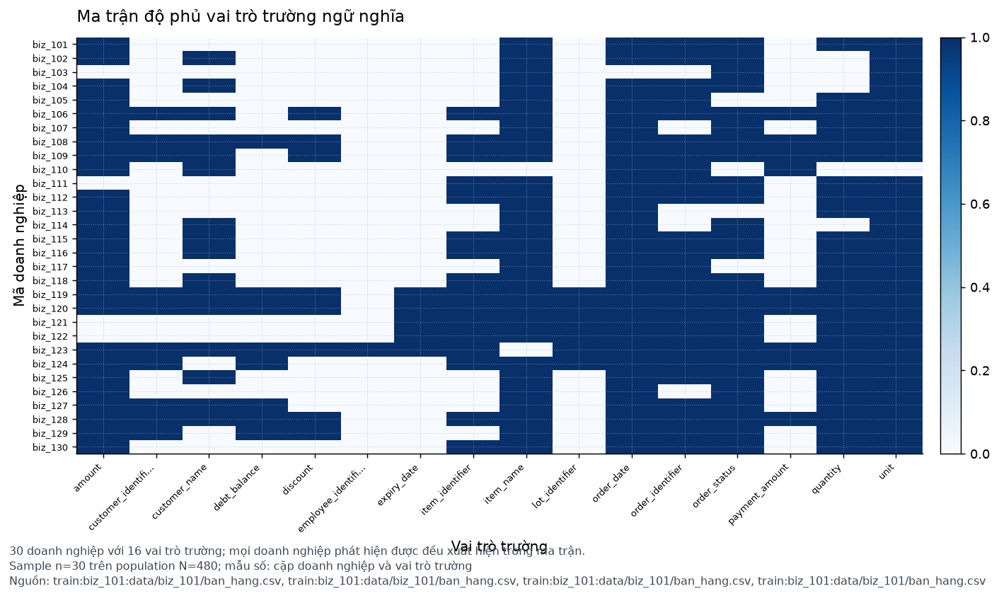


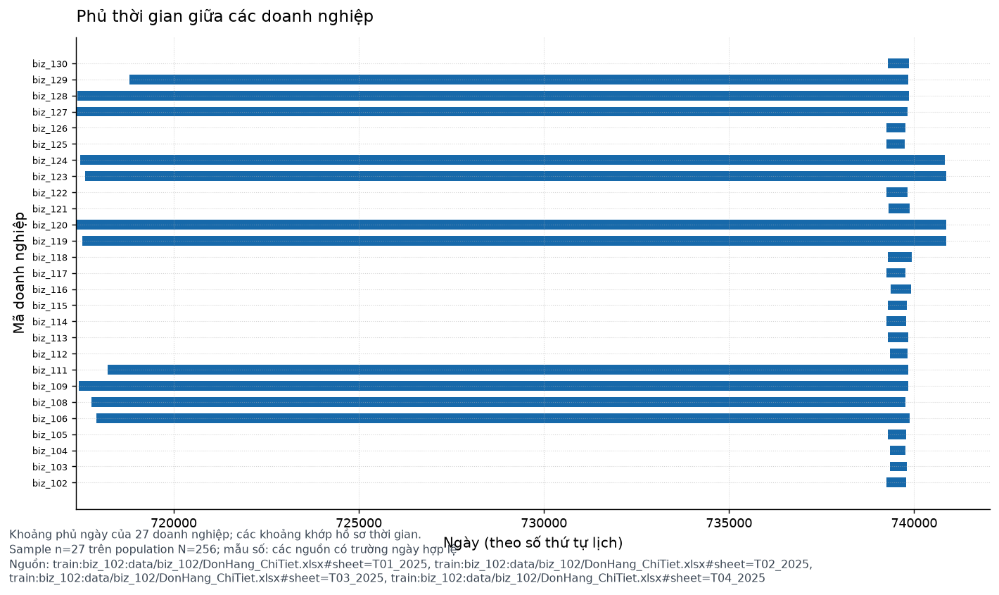


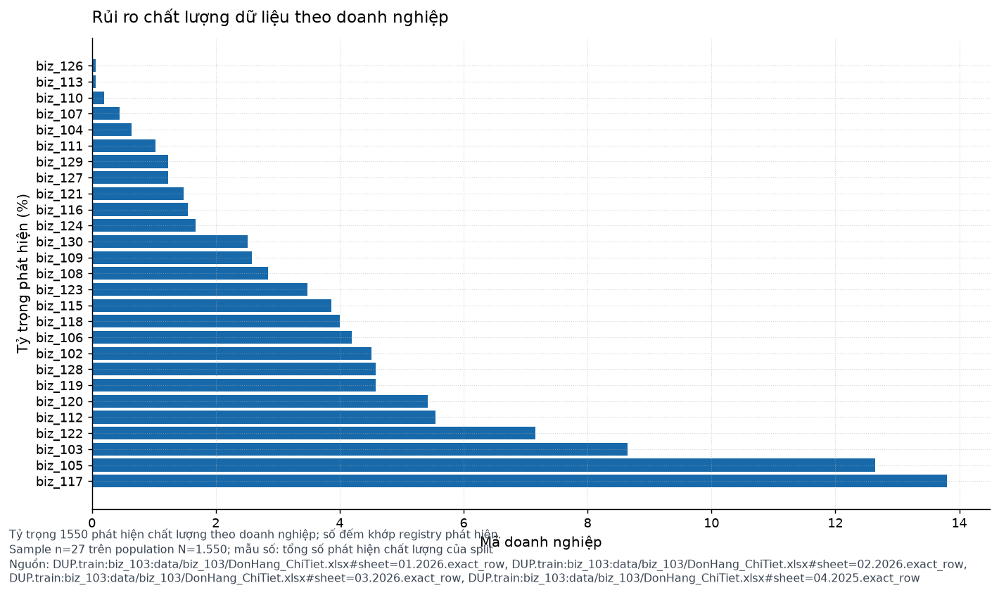


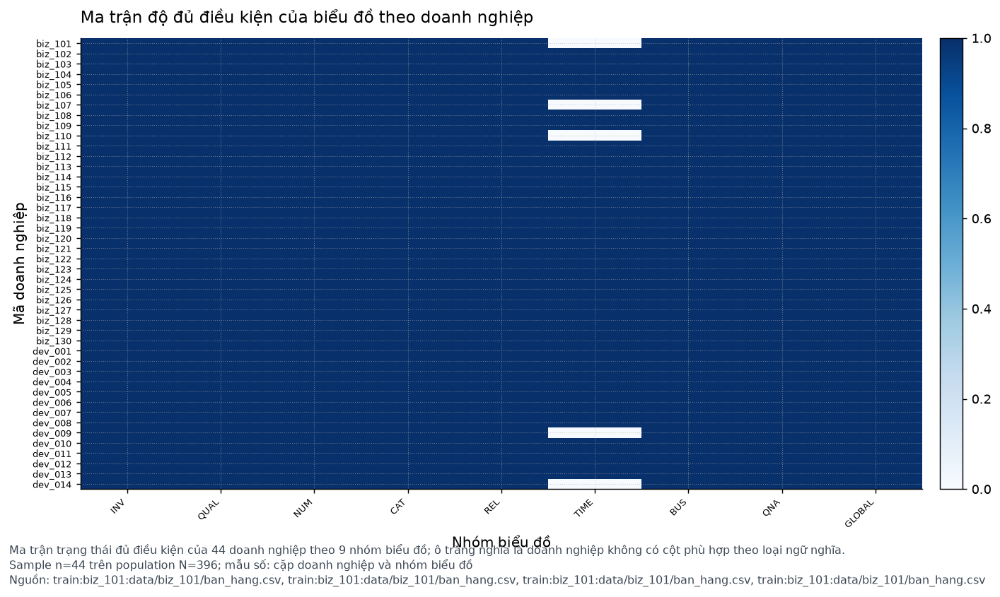

#### Thẻ chuyện `BUS01` — biz_101 (train)

1. **Mục tiêu:** Giá trị đơn hàng phân bố như thế nào?
2. **Bối cảnh:** split = train; doanh nghiệp = biz_101; nguồn = ('train:biz_101:data/biz_101/ban_hang.csv',); đơn vị quan sát = business_id
3. **Phương pháp:** phương pháp = valid_order_amount_distribution; quy tắc lọc = phân phối giá trị đơn hàng hợp lệ; xử lý giá trị khuyết = EXCLUDE_FROM_MEASURE_WITH_COUNT; xử lý ngoại lệ = RETAIN_AND_FLAG
4. **Bảng thống kê:**
   - population_n = 22428
   - n_valid = 22428
   - đơn vị = VND
   - phương pháp = valid_order_amount_distribution
   - công thức = phân phối giá trị đơn hàng hợp lệ
   - lấy mẫu = FULL_AGGREGATION
5. **Biểu đồ:** figures/20261029T155046Z_aa5c21e3/train/biz_101/BUS01.png
6. **Nhận xét:**
   - Trong `biz_101` thuộc split `public_test`, chỉ số `BUS01 — ban_hang.csv` có giá trị `66.000` `VND` trên `22.428` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T01_2025` có giá trị `66.000` `VND` trên `2.711` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T02_2025` có giá trị `65.000` `VND` trên `2.367` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T03_2025` có giá trị `66.000` `VND` trên `1.887` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T04_2025` có giá trị `67.500` `VND` trên `1.769` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T05_2025` có giá trị `65.000` `VND` trên `1.876` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public

In [17]:
_show_table('TBL17', 'train')

_show_figure('GLOBAL02', 'train', 1)
_show_figure('GLOBAL03', 'train', 1)
_show_figure('GLOBAL04', 'train', 1)
_show_figure('GLOBAL05', None, 1)

display(Markdown(run.story_cards_markdown(
    'train'
)[:2600]))


## 14. Phân tích dữ liệu toàn cục

**Mục tiêu:** Đối chiếu mức độ bao phủ giữa các split và giữa các doanh nghiệp ở mức siêu dữ liệu.

**Phương pháp:** Tổng hợp số tệp, số doanh nghiệp, số worksheet, số đối tượng CSDL và số phát hiện chất lượng theo từng split.

**Cách đọc và hạn chế:** Số lượng đối tượng siêu dữ liệu không phải số giao dịch và không được cộng chéo giữa các loại đối tượng.


split,business_count,pass_count,partial_count,blocked_count,total_findings,total_source_files,status,row_count_disclaimer
train,30,30,0,0,1550,162,PASS,"file, sheet and table counts are source object counts; rows are never summed across objects of different grain and are not transaction counts"
public_test,14,14,0,0,1683,97,PASS,"file, sheet and table counts are source object counts; rows are never summed across objects of different grain and are not transaction counts"



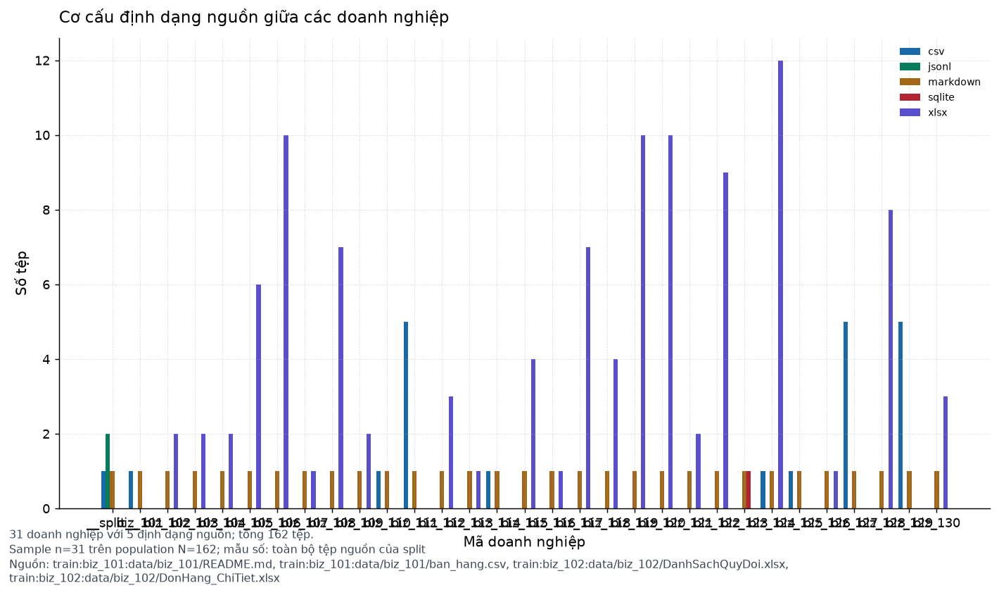


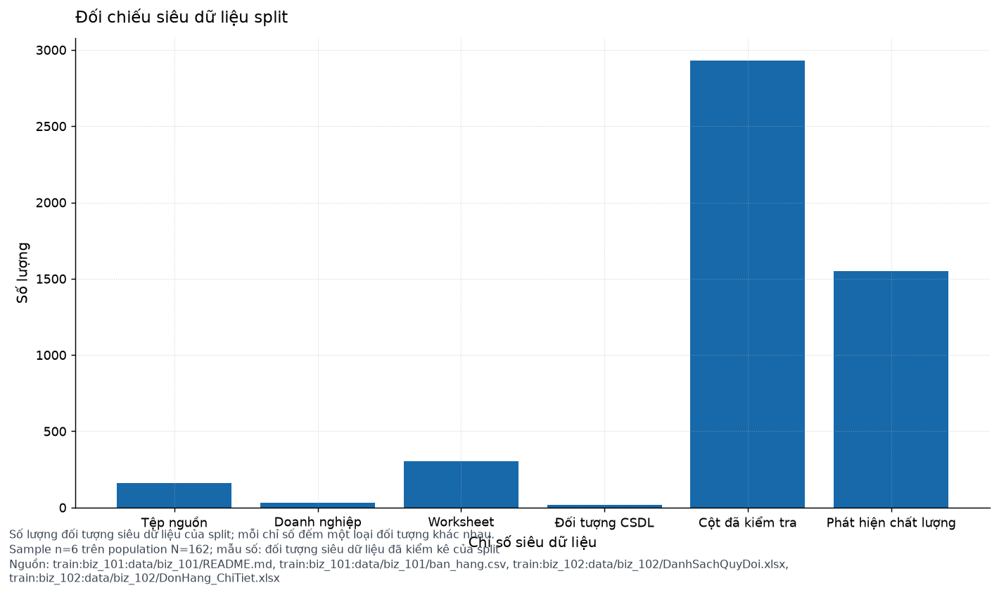

In [18]:
_show_table('TBL18')

_show_figure('GLOBAL01', 'train', 1)
_show_figure('GLOBAL06', 'train', 1)


## 15. Chất lượng và mức độ sẵn sàng cho tác nhân

**Mục tiêu:** Trình bày ledger kiểm định theo phase, trạng thái phát hiện chất lượng và danh mục phát hiện có bằng chứng.

**Phương pháp:** Mỗi gate ghi rõ phase, trạng thái, lý do và artifact chứng minh; mỗi phát hiện gắn mức độ, tỷ lệ và bằng chứng nguồn.

**Cách đọc và hạn chế:** Phân biệt phát hiện có bằng chứng với lỗi đã xác nhận; trạng thái BLOCKED là kết quả hợp lệ và không được nâng lên PASS để đạt hình thức.


finding_id,severity,domain,business_id,count,denominator,evidence,status,source_id,field,ratio,hypothesis,alternative_explanation,verification
DUP.train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=01.2026.exact_row,high,uniqueness,biz_103,1728,2937,exact_row duplicates=1728 distinct_keys=1209,PARTIAL,train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=01.2026,none,0.588355,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=02.2026.exact_row,high,uniqueness,biz_103,2861,4735,exact_row duplicates=2861 distinct_keys=1874,PARTIAL,train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=02.2026,none,0.604224,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=03.2026.exact_row,high,uniqueness,biz_103,1727,2904,exact_row duplicates=1727 distinct_keys=1177,PARTIAL,train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=03.2026,none,0.594697,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=04.2025.exact_row,high,uniqueness,biz_103,1654,2754,exact_row duplicates=1654 distinct_keys=1100,PARTIAL,train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=04.2025,none,0.600581,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=04.2026.exact_row,high,uniqueness,biz_103,1837,3004,exact_row duplicates=1837 distinct_keys=1167,PARTIAL,train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=04.2026,none,0.611518,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=05.2025.exact_row,high,uniqueness,biz_103,1719,2847,exact_row duplicates=1719 distinct_keys=1128,PARTIAL,train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=05.2025,none,0.603793,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=05.2026.exact_row,high,uniqueness,biz_103,1710,2855,exact_row duplicates=1710 distinct_keys=1145,PARTIAL,train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=05.2026,none,0.598949,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=06.2025.exact_row,high,uniqueness,biz_103,1563,2636,exact_row duplicates=1563 distinct_keys=1073,PARTIAL,train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=06.2025,none,0.592944,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.train:biz_103:data/biz_103/DonHang_ChiTiet.xlsx#sheet=06.2026.exact_row,high,uniqueness,biz_103,1659,2759,exact_row duplicates=1659 distinct_keys=1100,PARTIAL,train:biz_103:data/biz_103/DonHang_Chi

phase,gate,status,reason,owner,artifact
IMP-00,workspace_audit,PASS,"workspace root, raw root and output containment verified",orchestration.pipeline,run_manifest.json
IMP-01,split_inventory_train,PASS,"162 source files, 30 businesses, 302 worksheets, 17 database objects",orchestration.pipeline,file_manifest.json
IMP-02,schema_discovery_train,PASS,"2932 typed columns, 16712 key candidates, 294 relation candidates",orchestration.pipeline,column_registry.json
IMP-03,data_quality_train,PASS,"741 missingness entries, 590 duplicate classes, 36 validity rules, 1550 compiled findings",orchestration.pipeline,quality_findings.json
IMP-04,statistics_train,PASS,"602 numeric measures, 16492 categorical profiles",orchestration.pipeline,numeric_stats.json
IMP-05,temporal_train,PASS,"256 date columns, 256 coverage windows",orchestration.pipeline,temporal_profile.json
IMP-06,business_profiles_train,PASS,"30 business profiles, 30 domain diagnostics, 480 metric definitions",orchestration.pipeline,business_profile_index.json
IMP-07,question_metadata_train,PASS,3000 questions profiled; reference answers profiled in aggregated metadata form,orchestration.pipeline,question_profile.json
IMP-01,split_inventory_public_test,PASS,"97 source files, 14 businesses, 136 worksheets, 17 database objects",orchestration.pipeline,file_manifest.json
IMP-02,schema_discovery_public_test,PASS,"1445 typed columns, 7924 key candidates, 174 relation candidates",orchestration.pipeline,column_registry.json



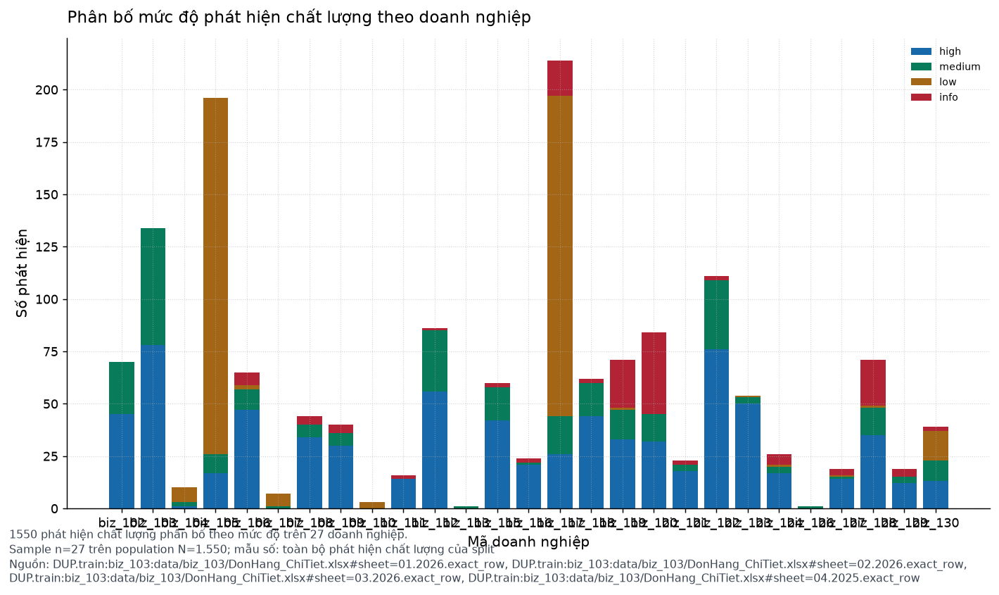


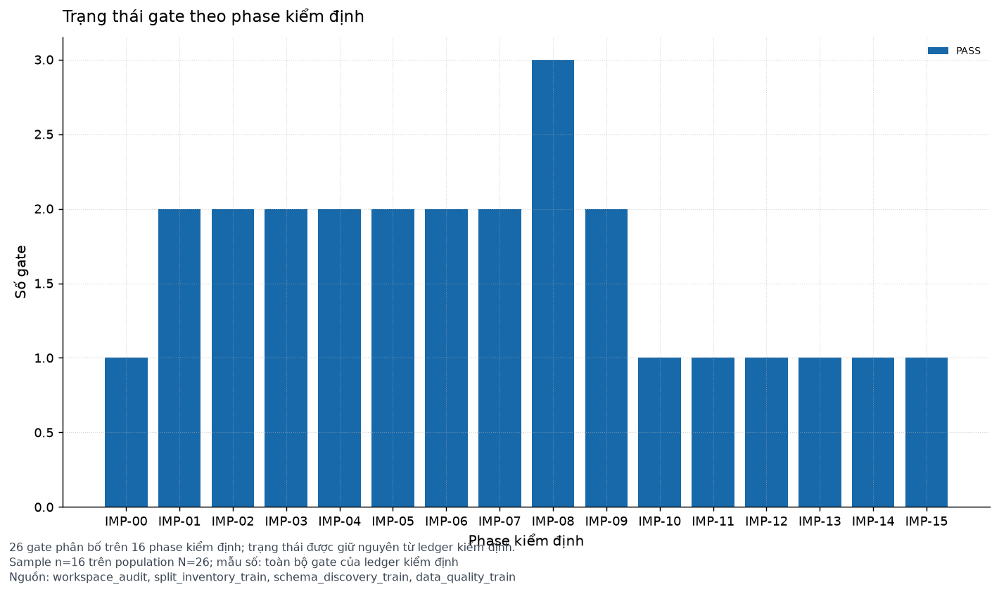

#### Thẻ chuyện `BUS01` — biz_101 (train)

1. **Mục tiêu:** Giá trị đơn hàng phân bố như thế nào?
2. **Bối cảnh:** split = train; doanh nghiệp = biz_101; nguồn = ('train:biz_101:data/biz_101/ban_hang.csv',); đơn vị quan sát = business_id
3. **Phương pháp:** phương pháp = valid_order_amount_distribution; quy tắc lọc = phân phối giá trị đơn hàng hợp lệ; xử lý giá trị khuyết = EXCLUDE_FROM_MEASURE_WITH_COUNT; xử lý ngoại lệ = RETAIN_AND_FLAG
4. **Bảng thống kê:**
   - population_n = 22428
   - n_valid = 22428
   - đơn vị = VND
   - phương pháp = valid_order_amount_distribution
   - công thức = phân phối giá trị đơn hàng hợp lệ
   - lấy mẫu = FULL_AGGREGATION
5. **Biểu đồ:** figures/20261029T155046Z_aa5c21e3/train/biz_101/BUS01.png
6. **Nhận xét:**
   - Trong `biz_101` thuộc split `public_test`, chỉ số `BUS01 — ban_hang.csv` có giá trị `66.000` `VND` trên `22.428` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T01_2025` có giá trị `66.000` `VND` trên `2.711` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T02_2025` có giá trị `65.000` `VND` trên `2.367` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T03_2025` có giá trị `66.000` `VND` trên `1.887` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T04_2025` có giá trị `67.500` `VND` trên `1.769` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T05_2025` có giá trị `65.000` `VND` trên `1.876` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public

In [19]:
_show_table('TBL19', 'train')
_show_table('TBL20')

_show_figure('QUAL06', 'train', 1)
_show_figure('QUAL08', None, 1)

display(Markdown(run.story_cards_markdown(
    'train'
)[:2600]))


## 16. Kết luận khoa học và bàn giao

**Mục tiêu:** Tổng hợp kết luận khoa học, hạn chế đã xác định và dòng dẫn tới từng artifact có hash để tái lập.

**Phương pháp:** Mỗi kết luận gắn mức tin cậy và đường dẫn bằng chứng; thẻ chuyện khoa học đính kèm theo từng nhóm nghiên cứu.

**Cách đọc và hạn chế:** Không có kết luận nào vượt quá phạm vi bằng chứng đã ghi; phần chưa đủ bằng chứng được nêu rõ thay vì bị lược bỏ.



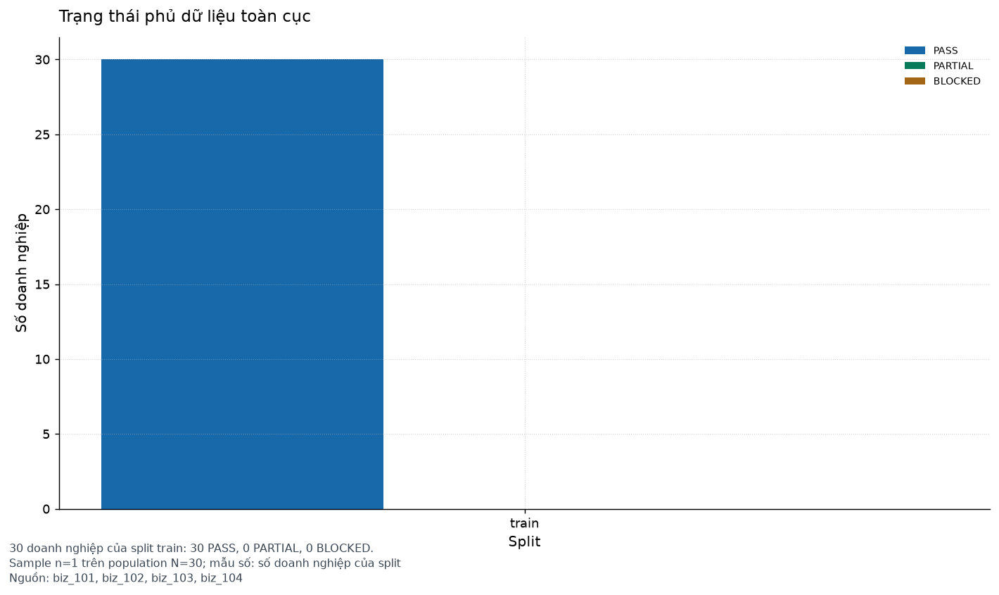

#### Thẻ chuyện `BUS01` — biz_101 (train)

1. **Mục tiêu:** Giá trị đơn hàng phân bố như thế nào?
2. **Bối cảnh:** split = train; doanh nghiệp = biz_101; nguồn = ('train:biz_101:data/biz_101/ban_hang.csv',); đơn vị quan sát = business_id
3. **Phương pháp:** phương pháp = valid_order_amount_distribution; quy tắc lọc = phân phối giá trị đơn hàng hợp lệ; xử lý giá trị khuyết = EXCLUDE_FROM_MEASURE_WITH_COUNT; xử lý ngoại lệ = RETAIN_AND_FLAG
4. **Bảng thống kê:**
   - population_n = 22428
   - n_valid = 22428
   - đơn vị = VND
   - phương pháp = valid_order_amount_distribution
   - công thức = phân phối giá trị đơn hàng hợp lệ
   - lấy mẫu = FULL_AGGREGATION
5. **Biểu đồ:** figures/20261029T155046Z_aa5c21e3/train/biz_101/BUS01.png
6. **Nhận xét:**
   - Trong `biz_101` thuộc split `public_test`, chỉ số `BUS01 — ban_hang.csv` có giá trị `66.000` `VND` trên `22.428` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T01_2025` có giá trị `66.000` `VND` trên `2.711` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T02_2025` có giá trị `65.000` `VND` trên `2.367` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T03_2025` có giá trị `66.000` `VND` trên `1.887` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T04_2025` có giá trị `67.500` `VND` trên `1.769` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T05_2025` có giá trị `65.000` `VND` trên `1.876` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T06_2025` có giá trị `64.500` `VND` trên `1.729` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T07_2025` có giá trị `65.000` `VND` trên `1.848` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T08_2025` có giá trị `68.000` `VND` trên `1.833` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T09_2025` có giá trị `67.000` `VND` trên `1.755` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T10_2025` có giá trị `69.000` `VND` trên `1.869` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T11_2025` có giá trị `74.000` `VND` trên `1.768` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T12_2025` có giá trị `65.000` `VND` trên `1.783` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T01_2026` có giá trị `71.400` `VND` trên `1.870` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T02_2026` có giá trị `68.900` `VND` trên `2.889` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T03_2026` có giá trị `74.500` `VND` trên `1.825` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T04_2026` có giá trị `72.000` `VND` trên `1.732` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T05_2026` có giá trị `69.200` `VND` trên `1.748` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_102` thuộc split `public_test`, chỉ số `BUS01 — T06_2026` có giá trị `73.300` `VND` trên `906` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_104` thuộc split `public_test`, chỉ số `BUS01 — Sheet1` có giá trị `55.000` `VND` trên `39.006` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_105` thuộc split `public_test`, chỉ số `BUS01 — Sheet1` có giá trị `3.653.800` `VND` trên `441` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_106` thuộc split `public_test`, chỉ số `BUS01 — Sheet1` có giá trị `56.000` `VND` trên `78.847` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_106` thuộc split `public_test`, chỉ số `BUS01 — Sheet1` có giá trị `58.000` `VND` trên `60.892` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_106` thuộc split `public_test`, chỉ số `BUS01 — Sheet1` có giá trị `58.500` `VND` trên `17.955` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_108` thuộc split `public_test`, chỉ số `BUS01 — Sheet1` có giá trị `67.500` `VND` trên `31.501` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_108` thuộc split `public_test`, chỉ số `BUS01 — Sheet1` có giá trị `67.500` `VND` trên `31.501` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_109` thuộc split `public_test`, chỉ số `BUS01 — Sheet1` có giá trị `69.700` `VND` trên `33.065` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_109` thuộc split `public_test`, chỉ số `BUS01 — DanhSachHoaDon` có giá trị `69.700` `VND` trên `33.065` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_111` thuộc split `public_test`, chỉ số `BUS01 — chi_tiet_don.csv` có giá trị `55.000` `VND` trên `66.469` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_111` thuộc split `public_test`, chỉ số `BUS01 — don_hang.csv` có giá trị `60.000` `VND` trên `66.469` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_112` thuộc split `public_test`, chỉ số `BUS01 — T04_2025` có giá trị `58.000` `VND` trên `4.068` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_112` thuộc split `public_test`, chỉ số `BUS01 — T05_2025` có giá trị `55.000` `VND` trên `4.303` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_112` thuộc split `public_test`, chỉ số `BUS01 — T06_2025` có giá trị `55.000` `VND` trên `4.314` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_112` thuộc split `public_test`, chỉ số `BUS01 — T07_2025` có giá trị `56.000` `VND` trên `4.328` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_112` thuộc split `public_test`, chỉ số `BUS01 — T08_2025` có giá trị `55.000` `VND` trên `4.653` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_112` thuộc split `public_test`, chỉ số `BUS01 — T09_2025` có giá trị `55.000` `VND` trên `4.323` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_112` thuộc split `public_test`, chỉ số `BUS01 — T10_2025` có giá trị `58.000` `VND` trên `4.444` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_112` thuộc split `public_test`, chỉ số `BUS01 — T11_2025` có giá trị `55.000` `VND` trên `4.526` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_112` thuộc split `public_test`, chỉ số `BUS01 — T12_2025` có giá trị `55.000` `VND` trên `4.536` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_112` thuộc split `public_test`, chỉ số `BUS01 — T01_2026` có giá trị `58.000` `VND` trên `4.616` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_112` thuộc split `public_test`, chỉ số `BUS01 — T02_2026` có giá trị `55.000` `VND` trên `3.295` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_112` thuộc split `public_test`, chỉ số `BUS01 — T03_2026` có giá trị `55.000` `VND` trên `4.706` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_112` thuộc split `public_test`, chỉ số `BUS01 — T04_2026` có giá trị `58.000` `VND` trên `4.551` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_112` thuộc split `public_test`, chỉ số `BUS01 — T05_2026` có giá trị `55.000` `VND` trên `4.878` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_112` thuộc split `public_test`, chỉ số `BUS01 — T06_2026` có giá trị `55.000` `VND` trên `4.431` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_112` thuộc split `public_test`, chỉ số `BUS01 — T07_2026` có giá trị `55.000` `VND` trên `4.806` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_115` thuộc split `public_test`, chỉ số `BUS01 — 02.2025` có giá trị `701.000` `VND` trên `684` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_115` thuộc split `public_test`, chỉ số `BUS01 — 03.2025` có giá trị `600.000` `VND` trên `923` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_115` thuộc split `public_test`, chỉ số `BUS01 — 04.2025` có giá trị `605.000` `VND` trên `888` quan sát ở grain `order` theo phương pháp `sum_line_amount_per_order_identifier`. Bộ lọc trạng thái áp dụng: `theo quy tắc trạng thái của rulebook split`. Nguồn: `finding.BUS01.dev_004`.
   - Trong `biz_115` thuộc split `public_test`, chỉ số `BUS01 — 05.2025` có giá trị `575.000` `VND` trên `906` quan sát ở grain `order`

In [20]:
_show_figure('GLOBAL07', 'train', 1)

display(Markdown(run.story_cards_markdown(
    'train'
)[:15600]))
